# Certificados de residencia: reglas automáticas de calidad y modelos de rechazo (ACA 2, v0.2)

**Especialización en Analítica de Datos, CUN.** Integrantes: Mónica Acevedo Sánchez e Ingrid Vanessa López Tautiva.

Este cuaderno desarrolla los objetivos específicos 2 y 3:

* **Objetivo 2.** Las reglas del ETL del objetivo 1 pasan a scripts reutilizables (`src/certificados`), escritos como transformadores de scikit-learn, y se mide su efecto con indicadores de calidad.
* **Objetivo 3.** Ingeniería de características, selección de variables, batería de modelos de menor a mayor complejidad con optimización equivalente en Optuna, validación temporal sin fuga, ablación y pruebas de robustez.

**Cómo correrlo:** *Entorno de ejecución > Ejecutar todo*. Con `REUTILIZAR_BUSQUEDA = True` (valor por defecto) se reutilizan los mejores hiperparámetros ya encontrados y guardados en `results/tables/optuna_trials.csv`, y el cuaderno corre en pocos minutos. Con `False` repite la búsqueda completa de Optuna (unos 40 minutos con 2 núcleos).

**Regla de reporte:** ninguna cifra se escribe a mano. Todas salen de este código y quedan en `results/`.

## 1. Configuración

In [1]:
import json, os, subprocess, sys, time, warnings
from datetime import date
from pathlib import Path

REPO_URL = 'https://github.com/monicaacevedos-stack/proyecto_certificados_residencia.git'
if Path('/content').exists() and not Path('proyecto_certificados_residencia').exists():
    subprocess.run(['git', 'clone', REPO_URL], check=True)
if Path('proyecto_certificados_residencia').exists():
    os.chdir('proyecto_certificados_residencia')
if Path.cwd().name == 'notebooks':
    os.chdir('..')
if Path('/content').exists():
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)

BASE = Path.cwd()
sys.path.insert(0, str(BASE/'src'))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from scipy import stats
from scipy.spatial.distance import jensenshannon
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_score

from certificados.calidad import aplicar_y_medir, medir
from certificados.caracteristicas import GRUPOS, TimeSeriesSplitPorDia, construir_base, preprocesador
from certificados.modelado import (AJUSTABLES, ESPACIOS, MODELOS, SIN_AJUSTE, UMBRAL, evaluar_cv, evaluar_prueba,
                                   sugerir)
from certificados.pipelines import PIPELINES
from certificados.reglas import MARCA_DIR, MARCA_ID, FaltantesExplicitos, NormalizadorComuna, es_dato_personal

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEMILLA = 42
np.random.seed(SEMILLA)
N_PRUEBAS_OPTUNA = 30          # mismo número de pruebas para todos los modelos
N_CORTES = 10                  # TimeSeriesSplit del protocolo (ACA 1, Tabla 3)
REUTILIZAR_BUSQUEDA = True
INICIO = time.perf_counter()
HOY = date.today().isoformat()

RAW, PROC = BASE/'data/raw', BASE/'data/processed'
TAB, FIG = BASE/'results/tables', BASE/'results/figures'
for carpeta in (TAB, FIG):
    carpeta.mkdir(parents=True, exist_ok=True)
EXPERIMENTOS = BASE/'results/experiments.csv'

AZUL, NARANJA, AGUA, TINTA, TINTA2, REJILLA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e4e3df', '#a3a29a'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'savefig.facecolor': 'white',
                     'font.family': 'DejaVu Sans', 'font.size': 10, 'text.color': TINTA, 'axes.labelcolor': TINTA2,
                     'axes.edgecolor': REJILLA, 'axes.grid': True, 'axes.axisbelow': True, 'grid.color': REJILLA, 'grid.linewidth': .7,
                     'xtick.color': TINTA2, 'ytick.color': TINTA2, 'xtick.bottom': False, 'ytick.left': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlelocation': 'left',
                     'axes.titlesize': 11.5, 'axes.titleweight': 'bold', 'figure.titlesize': 12, 'legend.frameon': False})

RES = {'interpretaciones': {}, 'titulos_figuras': {}, 'titulos_tablas': {}}

def mostrar(obj):
    try:
        display(obj)
    except NameError:
        print(obj)

def guardar_tabla(tabla, nombre, titulo, index=False):
    tabla.to_csv(TAB/f'{nombre}.csv', index=index, encoding='utf-8-sig')
    RES['titulos_tablas'][nombre] = titulo
    print(titulo)
    mostrar(tabla)

def guardar_figura(fig, nombre, titulo):
    fig.savefig(FIG/f'{nombre}.png')
    RES['titulos_figuras'][nombre] = titulo
    plt.show()
    plt.close(fig)

def interpretar(clave, texto):
    RES['interpretaciones'][clave] = texto
    print(f'Interpretación ({clave}): {texto}')

def pct(valor, dec=1):
    return f'{valor:.{dec}f}'.replace('.', ',')

def num(valor, dec=3):
    return f'{valor:.{dec}f}'.replace('.', ',')

def miles(valor):
    return f'{int(round(valor)):,}'.replace(',', '.')

CORRIDAS = []
def registrar_corrida(modelo, etapa, params, metr, semilla=SEMILLA, variables=None, nota=''):
    """Una fila por corrida en results/experiments.csv (fecha, modelo, parámetros, semilla y métricas)."""
    CORRIDAS.append({'fecha': HOY, 'id_corrida': len(CORRIDAS) + 1, 'etapa': etapa, 'modelo': modelo,
                     'parametros': json.dumps(params or {}, ensure_ascii=False, default=str), 'semilla': semilla,
                     'n_variables': len(variables) if variables is not None else None,
                     **{k: (round(float(v), 5) if isinstance(v, (int, float, np.floating)) and not pd.isna(v) else v) for k, v in metr.items()}, 'nota': nota})

def resumen(df, cols=('F1-macro', 'AUC-ROC', 'AUC-PR', 'MCC')):
    return {c: df[c].mean() for c in cols} | {f'{c} sd': df[c].std() for c in cols}

## 2. Objetivo específico 2: reglas automáticas de calidad

Las reglas viven en `src/certificados/reglas.py` y se arman en un `Pipeline` por fuente (`pipelines.py`). Cada regla hereda de `BaseEstimator` y `TransformerMixin`, como recomendó el docente: lo que se aprende de los datos (por ejemplo, los límites IQR) queda en `fit`, y `transform` aplica lo mismo a cualquier lote nuevo.

In [2]:
crudos = {'cartagena': pd.read_csv(sorted(RAW.glob('cartagena_*_enmascarado.csv'))[-1], dtype=str, encoding='utf-8'),
          'villavicencio': pd.read_csv(sorted(RAW.glob('villavicencio_*_enmascarado.csv'))[-1], dtype=str, encoding='utf-8')}
manifiestos = {k: json.loads(sorted(RAW.glob(f'{k}_*_manifiesto.json'))[-1].read_text(encoding='utf-8')) for k in crudos}
pipes = {k: PIPELINES[k]().fit(df) for k, df in crudos.items()}

QUE_HACE = {
    'renombrar': ('RenombrarColumnas', 'Armoniza los nombres de la API', 'No'),
    'enmascarar': ('EnmascaradorDatosPersonales', 'Reemplaza identificaciones y direcciones del texto libre por un marcador', 'No'),
    'tipos': ('TiposDeDato', 'Convierte fechas, números y booleanos', 'No'),
    'duplicados': ('EliminadorDuplicados', 'Quita filas repetidas y conserva la primera', 'No'),
    'codigo_faltante': ('IndicadorIgualdad', 'Marca el código escrito como No Aplica', 'No'),
    'retirar': ('RetirarColumnas', 'Retira la constante y el código que revela el resultado', 'No'),
    'texto': ('NormalizadorTexto', 'Mayúsculas, sin acentos, espacios simples y errata conocida', 'No'),
    'estados': ('FiltroEstadosFinales', 'Conserva trámites con decisión final y crea la variable objetivo', 'No'),
    'atipicos': ('MarcadorAtipicosIQR', 'Marca, sin alterar, el tiempo de residencia atípico', 'Sí: límites IQR'),
    'derivadas': ('DerivadasCartagena / DerivadasVillavicencio', 'Calendario e indicadores derivados', 'No'),
    'ordenar': ('Ordenar', 'Ordena por fecha', 'No'),
    'redundante': ('RetirarColumnas', 'Retira el código numérico redundante del estado', 'No'),
    'comuna': ('NormalizadorComuna', 'Lleva la comuna a un formato estándar o a Sin clasificar', 'No'),
    'finalidad': ('NormalizadorCategorias', 'Normaliza la finalidad y unifica equivalentes', 'No'),
    'faltantes': ('FaltantesExplicitos', 'Convierte vacíos en categorías explícitas (sin imputar)', 'No'),
    'retirar_barrio': ('RetirarColumnas', 'Retira el barrio por riesgo de reidentificación', 'No'),
}
filas = []
for ciudad, pipe in pipes.items():
    for i, (paso, _) in enumerate(pipe.steps, start=1):
        clase, hace, aprende = QUE_HACE[paso]
        filas.append({'Ciudad': ciudad.capitalize(), 'Paso': i, 'Regla (clase)': clase, 'Qué hace': hace, 'Aprende de los datos en fit': aprende})
tabla_reglas = pd.DataFrame(filas)
guardar_tabla(tabla_reglas, 'tabla_reglas_pipeline', 'Reglas de calidad convertidas en transformadores de scikit-learn, por fuente')

Reglas de calidad convertidas en transformadores de scikit-learn, por fuente


,Ciudad,Paso,Regla (clase),Qué hace,Aprende de los datos en fit
0,Cartagena,1,RenombrarColumnas,Armoniza los nombres de la API,No
1,Cartagena,2,EnmascaradorDatosPersonales,Reemplaza identificaciones y direcciones del t...,No
2,Cartagena,3,TiposDeDato,"Convierte fechas, números y booleanos",No
3,Cartagena,4,EliminadorDuplicados,Quita filas repetidas y conserva la primera,No
4,Cartagena,5,IndicadorIgualdad,Marca el código escrito como No Aplica,No
5,Cartagena,6,RetirarColumnas,Retira la constante y el código que revela el ...,No
6,Cartagena,7,NormalizadorTexto,"Mayúsculas, sin acentos, espacios simples y er...",No
7,Cartagena,8,FiltroEstadosFinales,Conserva trámites con decisión final y crea la...,No
8,Cartagena,9,MarcadorAtipicosIQR,"Marca, sin alterar, el tiempo de residencia at...",Sí: límites IQR
9,Cartagena,10,DerivadasCartagena / DerivadasVillavicencio,Calendario e indicadores derivados,No


### 2.1 ¿El script reproduce el ETL del objetivo 1?

In [3]:
filas = []
limpios_script = {}
for ciudad, fecha in (('cartagena', 'fecha_ingreso'), ('villavicencio', 'fecha_solicitud')):
    esperado = pd.read_csv(PROC/f'{ciudad}_limpio.csv', parse_dates=[fecha])
    t0 = time.perf_counter()
    p_comp = PIPELINES[ciudad]()
    obtenido = p_comp.fit_transform(crudos[ciudad])
    seg = time.perf_counter() - t0
    limpios_script[ciudad] = obtenido
    RES[f'dup_total_{ciudad}'] = p_comp.named_steps['duplicados'].retirados_
    releido = pd.read_csv(pd.io.common.StringIO(obtenido.to_csv(index=False)), parse_dates=[fecha])
    iguales = releido.shape == esperado.shape and list(releido.columns) == list(esperado.columns)
    distintas = int((releido.astype(str) != esperado.astype(str)).to_numpy().sum()) if iguales else -1
    filas.append({'Ciudad': ciudad.capitalize(), 'Registros ETL ACA 1': len(esperado), 'Registros script': len(obtenido),
                  'Variables ETL ACA 1': esperado.shape[1], 'Variables script': obtenido.shape[1], 'Celdas distintas': distintas,
                  'Segundos del script': round(seg, 3)})
tabla_equiv = pd.DataFrame(filas)
assert (tabla_equiv['Celdas distintas'] == 0).all()
guardar_tabla(tabla_equiv, 'tabla_equivalencia_scripts', 'Comparación entre la base limpia del ETL del ACA 1 y la producida por los scripts')
interpretar('tabla_equivalencia_scripts', f"Los scripts producen exactamente las mismas bases que el cuaderno del objetivo 1: {miles(tabla_equiv.loc[0, 'Registros script'])} registros en Cartagena y {miles(tabla_equiv.loc[1, 'Registros script'])} en Villavicencio, con cero celdas distintas. La misma comprobación corre como prueba automática (tests/test_equivalencia.py), así que cualquier cambio futuro en una regla que altere la base se detecta antes de usarla.")

Comparación entre la base limpia del ETL del ACA 1 y la producida por los scripts


,Ciudad,Registros ETL ACA 1,Registros script,Variables ETL ACA 1,Variables script,Celdas distintas,Segundos del script
0,Cartagena,14902,14902,17,17,0,0.121
1,Villavicencio,11615,11615,16,16,0,0.093


Interpretación (tabla_equivalencia_scripts): Los scripts producen exactamente las mismas bases que el cuaderno del objetivo 1: 14.902 registros en Cartagena y 11.615 en Villavicencio, con cero celdas distintas. La misma comprobación corre como prueba automática (tests/test_equivalencia.py), así que cualquier cambio futuro en una regla que altere la base se detecta antes de usarla.


### 2.2 Efecto de las reglas por lote mensual

Cada mes de la fuente se trata como si fuera un lote nuevo: el pipeline se ajusta una vez con la copia de referencia y luego se aplica a cada lote por separado.

Indicadores de calidad antes y después de aplicar los scripts a cada lote mensual


,Ciudad,Lote (mes),Registros entrada,Registros salida,Duplicados retirados,Completitud antes (%),Completitud después (%),Unicidad antes (%),Unicidad después (%),Conformidad antes (%),Conformidad después (%),Categorías antes,Categorías después,Milisegundos
0,Cartagena,2024-01,516,511,5,100.00,100.0,99.03,100.0,100.00,100.00,57,57,13.3
1,Cartagena,2024-02,574,573,1,100.00,100.0,99.83,100.0,99.83,100.00,67,67,13.2
2,Cartagena,2024-03,454,447,7,100.00,100.0,98.46,100.0,99.56,100.00,64,64,12.0
3,Cartagena,2024-04,863,857,6,100.00,100.0,99.30,100.0,99.77,100.00,75,75,13.8
4,Cartagena,2024-05,592,587,5,100.00,100.0,99.16,100.0,99.66,100.00,69,69,12.0
5,Cartagena,2024-06,755,747,7,100.00,100.0,99.07,100.0,100.00,100.00,76,76,14.9
6,Cartagena,2024-07,853,847,6,100.00,100.0,99.30,100.0,99.77,100.00,78,78,14.7
7,Cartagena,2024-08,258,257,1,100.00,100.0,99.61,100.0,100.00,100.00,54,54,9.9
8,Cartagena,2024-09,257,257,0,100.00,100.0,100.00,100.0,100.00,100.00,56,56,9.6
9,Cartagena,2024-10,418,417,1,100.00,100.0,99.76,100.0,100.00,100.00,60,60,11.5


Resumen de los indicadores de calidad en los lotes mensuales, peor lote antes y después de los scripts


,Ciudad,Lotes,Registros,Duplicados retirados,Completitud antes (mín. %),Completitud después (mín. %),Unicidad antes (mín. %),Unicidad después (mín. %),Conformidad antes (mín. %),Conformidad después (mín. %),Milisegundos por lote (mediana)
0,Cartagena,27,15007,97,100.00,100.0,96.89,100.0,98.04,100.00,12.3
1,Villavicencio,15,11622,7,99.07,100.0,99.83,100.0,92.81,97.96,14.3


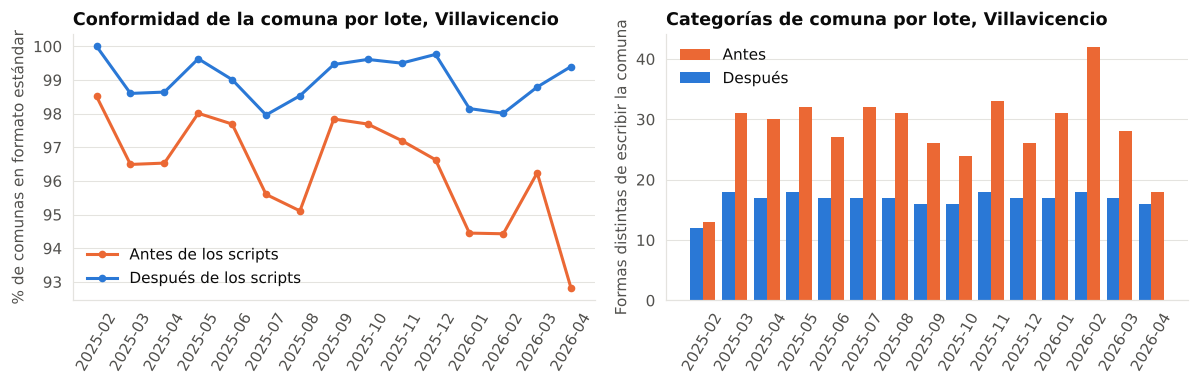

Interpretación (fig08_calidad_lotes): En los 15 lotes de Villavicencio la conformidad de la comuna sube en todos los meses; el valor mensual más bajo pasa de 92,8 % antes de los scripts a 98,0 % después. Lo que queda por debajo de 100 % son comunas que la regla no puede interpretar y deja como Sin clasificar en lugar de adivinarlas. Cada lote se procesa en una mediana de 14,3 milisegundos.
Interpretación (tabla_calidad_lotes_resumen): Aplicados lote por lote, los scripts dejan la unicidad en 100 % y la completitud en 100,0 % o más en todos los meses de ambas fuentes. En Cartagena retiran 97 duplicados, los mismos que en el procesamiento completo, porque todas las repeticiones caen dentro del mismo mes; aun así, en la operación real conviene comparar cada lote también contra el histórico, porque un reenvío puede llegar al mes siguiente.


In [4]:
filas = []
campo_fecha = {'cartagena': 'fecha_ingreso', 'villavicencio': 'fecha_y_hora_de_la_solicitud'}
for ciudad, crudo in crudos.items():
    meses = crudo[campo_fecha[ciudad]].str[:7]
    for mes, lote in crudo.groupby(meses):
        _, rep = aplicar_y_medir(lote.reset_index(drop=True), ciudad, pipes[ciudad])
        filas.append({'Ciudad': ciudad.capitalize(), 'Lote (mes)': mes, 'Registros entrada': rep['antes']['Registros'], 'Registros salida': rep['despues']['Registros'],
                      'Duplicados retirados': rep['duplicados_retirados'],
                      'Completitud antes (%)': rep['antes']['Completitud (%)'], 'Completitud después (%)': rep['despues']['Completitud (%)'],
                      'Unicidad antes (%)': rep['antes']['Unicidad (%)'], 'Unicidad después (%)': rep['despues']['Unicidad (%)'],
                      'Conformidad antes (%)': rep['antes']['Conformidad geográfica (%)'], 'Conformidad después (%)': rep['despues']['Conformidad geográfica (%)'],
                      'Categorías antes': rep['antes']['Categorías geográficas'], 'Categorías después': rep['despues']['Categorías geográficas'],
                      'Milisegundos': round(rep['segundos']*1000, 1)})
lotes = pd.DataFrame(filas)
guardar_tabla(lotes, 'tabla_calidad_por_lote', 'Indicadores de calidad antes y después de aplicar los scripts a cada lote mensual')

agg = lotes.groupby('Ciudad').agg(**{
    'Lotes': ('Lote (mes)', 'size'), 'Registros': ('Registros entrada', 'sum'), 'Duplicados retirados': ('Duplicados retirados', 'sum'),
    'Completitud antes (mín. %)': ('Completitud antes (%)', 'min'), 'Completitud después (mín. %)': ('Completitud después (%)', 'min'),
    'Unicidad antes (mín. %)': ('Unicidad antes (%)', 'min'), 'Unicidad después (mín. %)': ('Unicidad después (%)', 'min'),
    'Conformidad antes (mín. %)': ('Conformidad antes (%)', 'min'), 'Conformidad después (mín. %)': ('Conformidad después (%)', 'min'),
    'Milisegundos por lote (mediana)': ('Milisegundos', 'median')}).reset_index()
guardar_tabla(agg, 'tabla_calidad_lotes_resumen', 'Resumen de los indicadores de calidad en los lotes mensuales, peor lote antes y después de los scripts')

lv = lotes[lotes['Ciudad'] == 'Villavicencio']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(lv['Lote (mes)'], lv['Conformidad antes (%)'], color=NARANJA, lw=2, marker='o', ms=4, label='Antes de los scripts')
ax[0].plot(lv['Lote (mes)'], lv['Conformidad después (%)'], color=AZUL, lw=2, marker='o', ms=4, label='Después de los scripts')
ax[0].set_ylabel('% de comunas en formato estándar'); ax[0].set_title('Conformidad de la comuna por lote, Villavicencio'); ax[0].legend(loc='lower left'); ax[0].grid(axis='x', visible=False)
ax[0].tick_params(axis='x', rotation=60)
ax[1].bar(lv['Lote (mes)'], lv['Categorías antes'], color=NARANJA, width=.4, align='edge', label='Antes')
ax[1].bar(lv['Lote (mes)'], lv['Categorías después'], color=AZUL, width=-.4, align='edge', label='Después')
ax[1].set_ylabel('Formas distintas de escribir la comuna'); ax[1].set_title('Categorías de comuna por lote, Villavicencio'); ax[1].legend(); ax[1].grid(axis='x', visible=False)
ax[1].tick_params(axis='x', rotation=60)
fig.tight_layout()
guardar_figura(fig, 'fig08_calidad_lotes', 'Conformidad y número de categorías de la comuna antes y después de los scripts, por lote mensual, Villavicencio')
a_v, a_c = agg.set_index('Ciudad').loc['Villavicencio'], agg.set_index('Ciudad').loc['Cartagena']
RES['lotes'] = agg.to_dict('records')
interpretar('fig08_calidad_lotes', f"En los {int(a_v['Lotes'])} lotes de Villavicencio la conformidad de la comuna sube {'en todos los meses' if (lv['Conformidad después (%)'] > lv['Conformidad antes (%)']).all() else 'o se mantiene en todos los meses'}; el valor mensual más bajo pasa de {pct(a_v['Conformidad antes (mín. %)'])} % antes de los scripts a {pct(a_v['Conformidad después (mín. %)'])} % después. Lo que queda por debajo de 100 % son comunas que la regla no puede interpretar y deja como Sin clasificar en lugar de adivinarlas. Cada lote se procesa en una mediana de {pct(a_v['Milisegundos por lote (mediana)'])} milisegundos.")
assert (lv['Conformidad después (%)'] >= lv['Conformidad antes (%)']).all() and (lv['Categorías después'] <= lv['Categorías antes']).all()
assert (lotes['Unicidad después (%)'] == 100).all()
n_dup_lotes = int(a_c['Duplicados retirados'])
txt_dup = ('los mismos que en el procesamiento completo, porque todas las repeticiones caen dentro del mismo mes; aun así, en la operación real conviene comparar cada lote también contra el histórico, porque un reenvío puede llegar al mes siguiente'
           if n_dup_lotes == RES['dup_total_cartagena'] else f"menos que los {RES['dup_total_cartagena']} del procesamiento completo, porque un lote mensual no ve repeticiones que caen en meses distintos; por eso, en la operación real, cada lote debe compararse también contra el histórico")
interpretar('tabla_calidad_lotes_resumen', f"Aplicados lote por lote, los scripts dejan la unicidad en 100 % y la completitud en {pct(min(a_c['Completitud después (mín. %)'], a_v['Completitud después (mín. %)']))} % o más en todos los meses de ambas fuentes. En Cartagena retiran {n_dup_lotes} duplicados, {txt_dup}.")

### 2.3 Prueba de inyección de fallas

Para medir si las reglas detectan lo que deben, se insertan fallas conocidas en una muestra de registros limpios y se cuenta cuántas corrige el pipeline. Los valores inyectados son inventados (no corresponden a personas reales).

In [5]:
rng = np.random.default_rng(SEMILLA)
N_INY = 200
vv = crudos['villavicencio'].copy()
ok = vv['comuna_o_corregimiento'].map(lambda x: isinstance(x, str) and x.startswith('Comuna ')) & vv['barrio'].map(lambda x: isinstance(x, str) and x.isalpha())
base_v = vv[ok].sample(N_INY*5, random_state=SEMILLA).reset_index(drop=True)
base_v['id'] = np.arange(10**6, 10**6 + len(base_v)).astype(str)
bloques = np.array_split(np.arange(len(base_v)), 5)
iny = base_v.copy()
# 1) variantes de escritura de la comuna
variantes = [lambda n: f'comuna {n}', lambda n: f'COMUNA  0{n}', lambda n: f'Comuna{n} Villavicencio', lambda n: f' comuna {n} ', lambda n: f'COMUNA {n}']
esperada_comuna = iny.loc[bloques[0], 'comuna_o_corregimiento'].copy()
iny.loc[bloques[0], 'comuna_o_corregimiento'] = [variantes[i % 5](int(c.split()[1])) for i, c in enumerate(esperada_comuna)]
# 2) identificador de 10 dígitos dentro del barrio
iny.loc[bloques[1], 'barrio'] = [f'{b} {rng.integers(10**9, 10**10)}' for b in iny.loc[bloques[1], 'barrio']]
# 3) dirección escrita en el barrio
calles = ['CALLE', 'CARRERA', 'MZ', 'DIAGONAL', 'TRANSVERSAL']
iny.loc[bloques[2], 'barrio'] = [f'{calles[i % 5]} {rng.integers(1, 99)} # {rng.integers(1, 99)}-{rng.integers(1, 99)}' for i in range(len(bloques[2]))]
# 4) estado vacío
iny.loc[bloques[3], 'tramite'] = np.nan
# 5) duplicados: copias exactas con otro consecutivo
dups = iny.loc[bloques[4]].copy(); dups['id'] = (dups['id'].astype(int) + 10**7).astype(str)
iny = pd.concat([iny, dups], ignore_index=True)

pipe_iny = PIPELINES['villavicencio']()
pipe_iny.fit(iny)
fuera = pipe_iny.named_steps['enmascarar'].transform(pipe_iny.named_steps['renombrar'].transform(iny))
out = pipe_iny.transform(iny)
rep_enm = pipe_iny.named_steps['enmascarar'].reporte_
detect = {
    'Comuna escrita con variantes': int((NormalizadorComuna('comuna_o_corregimiento').fit_transform(iny.loc[bloques[0]])['comuna_o_corregimiento'].to_numpy() == esperada_comuna.to_numpy()).sum()),
    'Identificador de 10 dígitos en el barrio': int(fuera.loc[bloques[1], 'barrio'].eq(MARCA_ID).sum()),
    'Dirección escrita en el barrio': int(fuera.loc[bloques[2], 'barrio'].eq(MARCA_DIR).sum()),
    'Estado vacío': int(FaltantesExplicitos({'tramite': 'Sin estado'}).fit_transform(iny.loc[bloques[3]])['tramite'].eq('Sin estado').sum()),
    'Registro duplicado con otro consecutivo': int(pipe_iny.named_steps['duplicados'].retirados_),
}
falsos = int(fuera.loc[np.r_[bloques[0], bloques[3], bloques[4]], 'barrio'].isin([MARCA_ID, MARCA_DIR]).sum())
tabla_iny = pd.DataFrame([{'Falla inyectada': k, 'Casos inyectados': N_INY, 'Corregidos o detectados': v, '% de efectividad': round(v/N_INY*100, 1)} for k, v in detect.items()])
guardar_tabla(tabla_iny, 'tabla_inyeccion_fallas', 'Efectividad de las reglas frente a fallas inyectadas de forma controlada, Villavicencio')
cart_barrios = pd.Series(crudos['cartagena']['barrio_corregimiento'].unique())
fp_cart = int(cart_barrios.map(lambda x: x in (MARCA_ID, MARCA_DIR) or es_dato_personal(x) is not None).sum())
RES.update({'iny_falsos_positivos': falsos, 'iny_base_fp': int(len(bloques[0]) + len(bloques[3]) + len(bloques[4])), 'fp_barrios_cartagena': fp_cart, 'n_barrios_cartagena': int(len(cart_barrios))})
efect_min = tabla_iny['% de efectividad'].min()
interpretar('tabla_inyeccion_fallas', f"Las reglas corrigen o detectan {'el 100 %' if efect_min == 100 else 'al menos ' + pct(efect_min) + ' %'} de cada tipo de falla inyectada. Además, no enmascaran por error ninguno de los {RES['iny_base_fp']} barrios legítimos de los grupos de control ({falsos} falsos positivos) ni ninguno de los {len(cart_barrios)} nombres de barrio de Cartagena ({fp_cart}). La prueba solo cubre los patrones conocidos: una dirección escrita sin números o un identificador partido en bloques cortos no serían detectados, y por eso el enmascaramiento debe completarse con revisión humana antes de publicar.")

Efectividad de las reglas frente a fallas inyectadas de forma controlada, Villavicencio


,Falla inyectada,Casos inyectados,Corregidos o detectados,% de efectividad
0,Comuna escrita con variantes,200,200,100.0
1,Identificador de 10 dígitos en el barrio,200,200,100.0
2,Dirección escrita en el barrio,200,200,100.0
3,Estado vacío,200,200,100.0
4,Registro duplicado con otro consecutivo,200,200,100.0


Interpretación (tabla_inyeccion_fallas): Las reglas corrigen o detectan el 100 % de cada tipo de falla inyectada. Además, no enmascaran por error ninguno de los 600 barrios legítimos de los grupos de control (0 falsos positivos) ni ninguno de los 117 nombres de barrio de Cartagena (0). La prueba solo cubre los patrones conocidos: una dirección escrita sin números o un identificador partido en bloques cortos no serían detectados, y por eso el enmascaramiento debe completarse con revisión humana antes de publicar.


In [6]:
k_c, k_v = {}, {}
for ciudad in crudos:
    _, rep = aplicar_y_medir(crudos[ciudad], ciudad, pipes[ciudad])
    (k_c if ciudad == 'cartagena' else k_v).update(rep)
pers_orig = {k: sum(x['identificadores'] + x['direcciones'] for x in m['valores_enmascarados'].values()) for k, m in manifiestos.items()}
kpi = pd.DataFrame([
    {'Indicador': 'Completitud (%)', 'Cartagena antes': k_c['antes']['Completitud (%)'], 'Cartagena después': k_c['despues']['Completitud (%)'], 'Villavicencio antes': k_v['antes']['Completitud (%)'], 'Villavicencio después': k_v['despues']['Completitud (%)']},
    {'Indicador': 'Unicidad (%)', 'Cartagena antes': k_c['antes']['Unicidad (%)'], 'Cartagena después': k_c['despues']['Unicidad (%)'], 'Villavicencio antes': k_v['antes']['Unicidad (%)'], 'Villavicencio después': k_v['despues']['Unicidad (%)']},
    {'Indicador': 'Conformidad geográfica (%)', 'Cartagena antes': k_c['antes']['Conformidad geográfica (%)'], 'Cartagena después': k_c['despues']['Conformidad geográfica (%)'], 'Villavicencio antes': k_v['antes']['Conformidad geográfica (%)'], 'Villavicencio después': k_v['despues']['Conformidad geográfica (%)']},
    {'Indicador': 'Categorías geográficas', 'Cartagena antes': k_c['antes']['Categorías geográficas'], 'Cartagena después': k_c['despues']['Categorías geográficas'], 'Villavicencio antes': k_v['antes']['Categorías geográficas'], 'Villavicencio después': k_v['despues']['Categorías geográficas']},
    {'Indicador': 'Datos personales expuestos', 'Cartagena antes': pers_orig['cartagena'], 'Cartagena después': k_c['despues']['Datos personales expuestos'], 'Villavicencio antes': pers_orig['villavicencio'], 'Villavicencio después': k_v['despues']['Datos personales expuestos']},
    {'Indicador': 'Tiempo de ejecución (s)', 'Cartagena antes': 'Sin medición manual', 'Cartagena después': round(k_c['segundos'], 3), 'Villavicencio antes': 'Sin medición manual', 'Villavicencio después': round(k_v['segundos'], 3)},
])
guardar_tabla(kpi, 'tabla_kpi_automatizacion', 'Indicadores de calidad de la Tabla 4 medidos antes y después de los scripts')
RES['kpi_auto'] = kpi.to_dict('records')
interpretar('tabla_kpi_automatizacion', f"Con los indicadores fijados en el protocolo, los scripts llevan la unicidad a 100 % en ambas fuentes y la conformidad de la comuna de Villavicencio de {pct(k_v['antes']['Conformidad geográfica (%)'], 2)} % a {pct(k_v['despues']['Conformidad geográfica (%)'], 2)} %, con {k_v['despues']['Categorías geográficas']} categorías en lugar de {k_v['antes']['Categorías geográficas']}. Los {pers_orig['villavicencio']} datos personales de la descarga original quedan en cero. La base completa de cada fuente se procesa en menos de {pct(max(k_c['segundos'], k_v['segundos']) + .05, 1)} segundos; sigue sin existir una medición del proceso manual para comparar ese tiempo.")

Indicadores de calidad de la Tabla 4 medidos antes y después de los scripts


,Indicador,Cartagena antes,Cartagena después,Villavicencio antes,Villavicencio después
0,Completitud (%),100.0,100.000,99.9,100.000
1,Unicidad (%),99.35,100.000,99.94,100.000
2,Conformidad geográfica (%),99.52,100.000,96.6,98.980
3,Categorías geográficas,117,117.000,87,18.000
4,Datos personales expuestos,0,0.000,68,0.000
5,Tiempo de ejecución (s),Sin medición manual,0.126,Sin medición manual,0.108


Interpretación (tabla_kpi_automatizacion): Con los indicadores fijados en el protocolo, los scripts llevan la unicidad a 100 % en ambas fuentes y la conformidad de la comuna de Villavicencio de 96,60 % a 98,98 %, con 18 categorías en lugar de 87. Los 68 datos personales de la descarga original quedan en cero. La base completa de cada fuente se procesa en menos de 0,2 segundos; sigue sin existir una medición del proceso manual para comparar ese tiempo.


## 3. Objetivo específico 3: modelos de clasificación del rechazo

### 3.1 Partición temporal

Se separa la prueba **antes de cualquier transformación que aprenda de los datos**: el último 20 % de los registros por fecha. Para que un mismo día no quede partido entre entrenamiento y prueba, el corte se mueve al inicio del día en que cae el percentil 80.

In [7]:
c = pd.read_csv(PROC/'cartagena_limpio.csv', parse_dates=['fecha_ingreso'])
base = construir_base(c)  # rezagos con datos anteriores, calendario y dominio: no aprenden parámetros
CORTE = base['fecha_ingreso'].iloc[int(len(base)*.8)].normalize()
es_prueba = base['fecha_ingreso'] >= CORTE
ent, pru = base[~es_prueba].reset_index(drop=True), base[es_prueba].reset_index(drop=True)
y_ent, y_pru = ent['rechazo'], pru['rechazo']
cv = TimeSeriesSplitPorDia(N_CORTES)
cortes = list(cv.split(ent, y_ent, fechas=ent['fecha_ingreso']))
part = pd.DataFrame([
    {'Bloque': 'Entrenamiento y validación', 'Desde': ent['fecha_ingreso'].min().date(), 'Hasta': ent['fecha_ingreso'].max().date(), 'Registros': len(ent), '% del total': round(len(ent)/len(base)*100, 1), 'Rechazos': int(y_ent.sum()), '% rechazo': round(y_ent.mean()*100, 2)},
    {'Bloque': 'Prueba final', 'Desde': pru['fecha_ingreso'].min().date(), 'Hasta': pru['fecha_ingreso'].max().date(), 'Registros': len(pru), '% del total': round(len(pru)/len(base)*100, 1), 'Rechazos': int(y_pru.sum()), '% rechazo': round(y_pru.mean()*100, 2)},
] + [{'Bloque': f'Corte {k} (validación)', 'Desde': ent['fecha_ingreso'].iloc[va].min().date(), 'Hasta': ent['fecha_ingreso'].iloc[va].max().date(), 'Registros': len(va), '% del total': round(len(va)/len(base)*100, 1), 'Rechazos': int(y_ent.iloc[va].sum()), '% rechazo': round(y_ent.iloc[va].mean()*100, 2)} for k, (tr, va) in enumerate(cortes, start=1)])
guardar_tabla(part, 'tabla_particion', 'Partición temporal: bloque de entrenamiento y validación, cortes de TimeSeriesSplit y prueba final')
assert ent['fecha_ingreso'].max() < pru['fecha_ingreso'].min()
assert all(ent['fecha_ingreso'].iloc[tr].max() < ent['fecha_ingreso'].iloc[va].min() for tr, va in cortes)
RES.update({'corte': str(CORTE.date()), 'n_ent': len(ent), 'n_pru': len(pru), 'tasa_ent': float(y_ent.mean()*100), 'tasa_pru': float(y_pru.mean()*100),
            'val_min': int(min(len(va) for _, va in cortes)), 'val_max': int(max(len(va) for _, va in cortes))})
interpretar('tabla_particion', f"La prueba final empieza el {CORTE.date()} y reúne {miles(len(pru))} solicitudes ({pct(len(pru)/len(base)*100)} %), con una tasa de rechazo de {pct(y_pru.mean()*100)} % frente a {pct(y_ent.mean()*100)} % en el bloque de entrenamiento. Los {N_CORTES} cortes de validación avanzan en el tiempo y ninguno usa fechas posteriores a las de su entrenamiento. La tasa de rechazo de la prueba duplica la del entrenamiento: es la deriva que se analiza a continuación.")

Partición temporal: bloque de entrenamiento y validación, cortes de TimeSeriesSplit y prueba final


,Bloque,Desde,Hasta,Registros,% del total,Rechazos,% rechazo
0,Entrenamiento y validación,2024-01-02,2026-01-05,11907,79.9,1017,8.54
1,Prueba final,2026-01-06,2026-03-31,2995,20.1,563,18.80
2,Corte 1 (validación),2024-03-12,2024-05-16,1493,10.0,220,14.74
3,Corte 2 (validación),2024-05-17,2024-07-22,1694,11.4,177,10.45
4,Corte 3 (validación),2024-07-23,2024-09-28,641,4.3,37,5.77
5,Corte 4 (validación),2024-09-29,2024-12-04,807,5.4,47,5.82
6,Corte 5 (validación),2024-12-05,2025-02-08,1164,7.8,59,5.07
7,Corte 6 (validación),2025-02-09,2025-04-13,1206,8.1,99,8.21
8,Corte 7 (validación),2025-04-14,2025-06-20,659,4.4,59,8.95
9,Corte 8 (validación),2025-06-21,2025-08-27,989,6.6,39,3.94


Interpretación (tabla_particion): La prueba final empieza el 2026-01-06 y reúne 2.995 solicitudes (20,1 %), con una tasa de rechazo de 18,8 % frente a 8,5 % en el bloque de entrenamiento. Los 10 cortes de validación avanzan en el tiempo y ninguno usa fechas posteriores a las de su entrenamiento. La tasa de rechazo de la prueba duplica la del entrenamiento: es la deriva que se analiza a continuación.


### 3.2 Cambio de distribución entre entrenamiento y prueba (deriva)

Recomendación del docente: antes de modelar, medir cuánto cambian las variables predictoras entre el 80 % temporal inicial y el 20 % final, para saber si un bajo desempeño en prueba se explicaría por un cambio en las covariables o por un cambio en los criterios de rechazo.

Cambio de distribución entre el bloque de entrenamiento (80 % inicial) y la prueba (20 % final), Cartagena


,Variable,Tipo,Distancia de Jensen-Shannon,KS,p,AUC adversaria
0,volumen_7d_previo,Numérica,0.611,0.575,0.000000e+00,NaN
1,rechazo (variable objetivo),Categórica,0.128,NaN,1.770000e-59,NaN
2,tipo_documento,Categórica,0.115,NaN,1.130000e-28,NaN
3,barrio (20 + otros),Categórica,0.090,NaN,6.510000e-12,NaN
4,tiempo_residencia_anios,Numérica,0.067,0.056,5.540000e-07,NaN
5,dia_semana,Categórica,0.026,NaN,1.820000e-01,NaN
6,calidad_solicitante,Categórica,0.001,NaN,9.260000e-01,NaN
7,Validación adversaria (AUC entrenamiento frent...,Conjunta,NaN,NaN,NaN,0.578


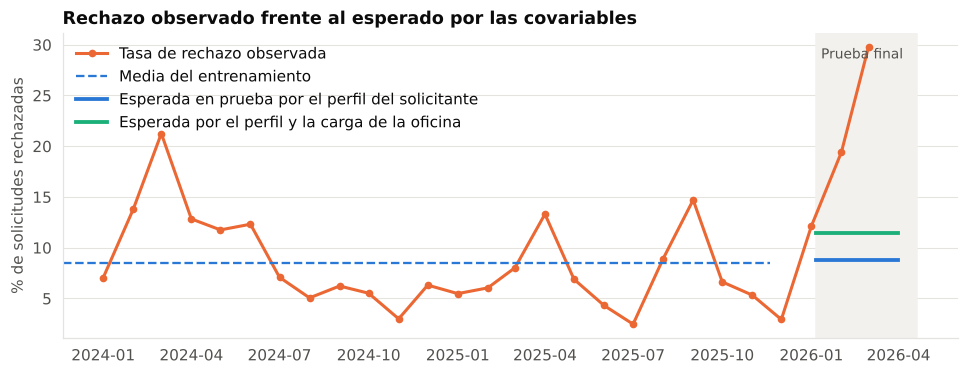

Interpretación (tabla_deriva): Sí hay deriva en las covariables. La más fuerte es la carga de la oficina: las solicitudes de los 7 días previos pasan de una media de 137 a 294 (Jensen-Shannon de 0,611). También cambia el perfil: la tarjeta de identidad baja de 6,6 % a 1,6 % de las solicitudes (distancia de 0,115 en el tipo de documento). El barrio y el tiempo de residencia cambian poco (distancias de 0,090 y 0,067), y un clasificador que intenta distinguir entrenamiento de prueba con las variables del solicitante solo alcanza un AUC de 0,578.
Interpretación (fig09_deriva): Si solo hubiera cambiado el perfil de quienes solicitan, la tasa de rechazo esperada en la prueba sería 8,8 %; al agregar la carga de la oficina sube a 11,5 %. La observada es 18,8 %. Además, dentro de un mismo tipo de documento la tasa se duplica: con cédula de ciudadanía pasa de 8,8 % a 18,8 %. La mayor parte del alza no se explica por quién solicita, sino por un cambio de criterio o de registro en 2026 que coincid

In [8]:
def js_categorica(a, b):
    cats = sorted(set(a.astype(str)) | set(b.astype(str)))
    p = a.astype(str).value_counts(normalize=True).reindex(cats, fill_value=0)
    q = b.astype(str).value_counts(normalize=True).reindex(cats, fill_value=0)
    return float(jensenshannon(p, q, base=2)), float(stats.chi2_contingency(pd.crosstab(pd.concat([a, b]).astype(str), np.r_[np.zeros(len(a)), np.ones(len(b))]))[1])

def js_numerica(a, b, bins):
    p, _ = np.histogram(a, bins=bins); q, _ = np.histogram(b, bins=bins)
    return float(jensenshannon(p/p.sum(), q/q.sum(), base=2))

top20 = ent['barrio'].value_counts().head(20).index
filas = []
for nombre, a, b in [('barrio (20 + otros)', ent['barrio'].where(ent['barrio'].isin(top20), 'OTROS'), pru['barrio'].where(pru['barrio'].isin(top20), 'OTROS')),
                     ('tipo_documento', ent['tipo_documento'], pru['tipo_documento']), ('calidad_solicitante', ent['calidad_solicitante'], pru['calidad_solicitante']),
                     ('dia_semana', ent['dia_semana'], pru['dia_semana']), ('rechazo (variable objetivo)', ent['rechazo'], pru['rechazo'])]:
    js, p = js_categorica(a, b)
    filas.append({'Variable': nombre, 'Tipo': 'Categórica', 'Distancia de Jensen-Shannon': round(js, 3), 'KS': np.nan, 'p': float(f'{p:.3g}')})
for nombre, bins in [('tiempo_residencia_anios', np.arange(0, 70, 5)), ('volumen_7d_previo', np.linspace(0, max(ent['volumen_7d_previo'].max(), pru['volumen_7d_previo'].max()), 15))]:
    ks = stats.ks_2samp(ent[nombre], pru[nombre])
    filas.append({'Variable': nombre, 'Tipo': 'Numérica', 'Distancia de Jensen-Shannon': round(js_numerica(ent[nombre], pru[nombre], bins), 3), 'KS': round(ks.statistic, 3), 'p': float(f'{ks.pvalue:.3g}')})
deriva = pd.DataFrame(filas).sort_values('Distancia de Jensen-Shannon', ascending=False)

# Validación adversaria: ¿un clasificador distingue entrenamiento de prueba con las covariables del solicitante?
cov = ['tiempo_residencia_anios', 'tipo_documento', 'barrio_te', 'barrio_frecuencia', 'es_representacion']
Xa = pd.concat([ent, pru], ignore_index=True); ya = np.r_[np.zeros(len(ent)), np.ones(len(pru))]
from sklearn.pipeline import make_pipeline
adv = make_pipeline(preprocesador(cov, SEMILLA), LogisticRegression(max_iter=2000, class_weight='balanced'))
auc_adv = cross_val_score(adv, Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA), scoring='roc_auc')
# Tasa esperada en prueba si los criterios no hubieran cambiado: modelo sin pesos ajustado en entrenamiento
esp = make_pipeline(preprocesador(cov, SEMILLA), LogisticRegression(max_iter=2000)).fit(ent, y_ent)
tasa_esperada = float(esp.predict_proba(pru)[:, 1].mean()*100)
cov_carga = cov + ['volumen_7d_previo', 'volumen_30d_previo']
esp2 = make_pipeline(preprocesador(cov_carga, SEMILLA), LogisticRegression(max_iter=2000)).fit(ent, y_ent)
tasa_esperada_carga = float(esp2.predict_proba(pru)[:, 1].mean()*100)
por_doc = pd.DataFrame({'% entrenamiento': ent['tipo_documento'].value_counts(normalize=True)*100, '% prueba': pru['tipo_documento'].value_counts(normalize=True)*100,
                        '% rechazo entrenamiento': ent.groupby('tipo_documento')['rechazo'].mean()*100, '% rechazo prueba': pru.groupby('tipo_documento')['rechazo'].mean()*100}).round(2)
deriva = pd.concat([deriva, pd.DataFrame([{'Variable': 'Validación adversaria (AUC entrenamiento frente a prueba)', 'Tipo': 'Conjunta', 'Distancia de Jensen-Shannon': np.nan, 'KS': np.nan, 'p': np.nan, 'AUC adversaria': round(auc_adv.mean(), 3)}])], ignore_index=True)
guardar_tabla(deriva, 'tabla_deriva', 'Cambio de distribución entre el bloque de entrenamiento (80 % inicial) y la prueba (20 % final), Cartagena')
dj = deriva.set_index('Variable')['Distancia de Jensen-Shannon']
max_cov = dj.drop(['rechazo (variable objetivo)', 'Validación adversaria (AUC entrenamiento frente a prueba)']).idxmax()
RES.update({'auc_adv': float(auc_adv.mean()), 'tasa_esperada': tasa_esperada, 'tasa_esperada_carga': tasa_esperada_carga, 'por_doc': por_doc.to_dict('index'),
            'vol7_ent': float(ent['volumen_7d_previo'].mean()), 'vol7_pru': float(pru['volumen_7d_previo'].mean()), 'js_objetivo': float(dj['rechazo (variable objetivo)']), 'js_max_cov': float(dj[max_cov]), 'js_max_cov_var': max_cov})

mens = base.groupby(pd.Grouper(key='fecha_ingreso', freq='MS'))['rechazo'].mean()*100
fig, ax = plt.subplots(figsize=(10.5, 3.6))
ax.axvspan(CORTE, base['fecha_ingreso'].max() + pd.Timedelta(days=20), color='#f2f1ee')
ax.plot(mens.index, mens.values, color=NARANJA, lw=2, marker='o', ms=4, label='Tasa de rechazo observada')
ax.axhline(y_ent.mean()*100, xmax=.79, color=AZUL, lw=1.5, ls='--', label='Media del entrenamiento')
ax.plot([CORTE, base['fecha_ingreso'].max()], [tasa_esperada]*2, color=AZUL, lw=2.5, label='Esperada en prueba por el perfil del solicitante')
ax.plot([CORTE, base['fecha_ingreso'].max()], [tasa_esperada_carga]*2, color=AGUA, lw=2.5, label='Esperada por el perfil y la carga de la oficina')
ax.text(CORTE + pd.Timedelta(days=5), ax.get_ylim()[1]*.92, 'Prueba final', color=TINTA2, fontsize=9)
ax.set_ylabel('% de solicitudes rechazadas'); ax.set_title('Rechazo observado frente al esperado por las covariables'); ax.legend(loc='upper left'); ax.grid(axis='x', visible=False)
guardar_figura(fig, 'fig09_deriva', 'Tasa mensual de rechazo observada y tasa esperada en la prueba si solo cambiaran las covariables, Cartagena')
cc = por_doc.loc['Cédula de ciudadanía']
ti = por_doc.loc['Tarjeta de identidad']
assert tasa_esperada_carga < y_pru.mean()*100 - 5 and cc['% rechazo prueba'] > 1.8*cc['% rechazo entrenamiento']
assert dj['volumen_7d_previo'] == dj.max() and dj['calidad_solicitante'] < .05 and dj['tiempo_residencia_anios'] < .1
interpretar('tabla_deriva', f"Sí hay deriva en las covariables. La más fuerte es la carga de la oficina: las solicitudes de los 7 días previos pasan de una media de {pct(ent['volumen_7d_previo'].mean(), 0)} a {pct(pru['volumen_7d_previo'].mean(), 0)} (Jensen-Shannon de {num(dj['volumen_7d_previo'])}). También cambia el perfil: la tarjeta de identidad baja de {pct(ti['% entrenamiento'])} % a {pct(ti['% prueba'])} % de las solicitudes (distancia de {num(dj['tipo_documento'])} en el tipo de documento). El barrio y el tiempo de residencia cambian poco (distancias de {num(dj['barrio (20 + otros)'])} y {num(dj['tiempo_residencia_anios'])}), y un clasificador que intenta distinguir entrenamiento de prueba con las variables del solicitante solo alcanza un AUC de {num(auc_adv.mean())}.")
interpretar('fig09_deriva', f"Si solo hubiera cambiado el perfil de quienes solicitan, la tasa de rechazo esperada en la prueba sería {pct(tasa_esperada)} %; al agregar la carga de la oficina sube a {pct(tasa_esperada_carga)} %. La observada es {pct(y_pru.mean()*100)} %. Además, dentro de un mismo tipo de documento la tasa se duplica: con cédula de ciudadanía pasa de {pct(cc['% rechazo entrenamiento'])} % a {pct(cc['% rechazo prueba'])} %. La mayor parte del alza no se explica por quién solicita, sino por un cambio de criterio o de registro en 2026 que coincide con el aumento de la demanda; con estos datos no se pueden separar esas dos causas. Por eso se anticipa que la prueba será más difícil que la validación.")

### 3.3 Ingeniería de características

Tres familias deterministas se calculan sobre la base ordenada por fecha (`construir_base`) y una cuarta se aprende dentro del `Pipeline`, solo con el entrenamiento de cada corte.

In [9]:
DEF = [
 ('tiempo_residencia_anios', 'Residencia', 'Valor declarado (años)', 'Variable original del dominio; base de las demás de residencia', 'Original'),
 ('log_tiempo_residencia', 'Residencia', 'ln(1 + tiempo)', 'Reduce la asimetría positiva (0,66) encontrada en el EDA', 'Determinista'),
 ('tiempo_cero', 'Residencia', '1 si tiempo = 0', 'Falla de exactitud del catálogo (611 casos): puede asociarse con rechazo', 'Determinista'),
 ('tiempo_decimal', 'Residencia', '1 si tiempo tiene decimales', 'Falla de consistencia del catálogo (802 casos)', 'Determinista'),
 ('atipico_tiempo', 'Residencia', '1 si tiempo fuera de [Q1 - 1,5·IQR, Q3 + 1,5·IQR]', 'Límites aprendidos solo con el entrenamiento de cada corte', 'Aprendida en el Pipeline'),
 ('es_menor', 'Solicitante y documento', '1 si tarjeta de identidad o registro civil', 'Único hallazgo estable del EDA: menos rechazo en los 5 semestres', 'Determinista'),
 ('es_extranjero', 'Solicitante y documento', '1 si cédula de extranjería', 'Requisitos documentales distintos', 'Determinista'),
 ('es_representacion', 'Solicitante y documento', '1 si actúa en representación de otra persona', 'Trámite hecho por un tercero', 'Determinista'),
 ('juramento', 'Solicitante y documento', '1 si marcó el juramento', 'Requisito formal de la solicitud', 'Determinista'),
 ('tipo_documento', 'Solicitante y documento', 'One-hot (categorías con al menos 20 casos)', 'Codificación de la categórica; lo raro se agrupa', 'Aprendida en el Pipeline'),
 ('barrio_te', 'Barrio', 'Codificación por objetivo con validación cruzada interna (TargetEncoder)', '117 barrios: one-hot daría muchas columnas dispersas; V de Cramér del barrio = 0,125', 'Aprendida en el Pipeline'),
 ('barrio_frecuencia', 'Barrio', 'Proporción de solicitudes del barrio en el entrenamiento', 'Reemplaza frecuencia_barrio del EDA, que usaba toda la base (fuga)', 'Aprendida en el Pipeline'),
 ('tasa_rechazo_barrio_previa_90d', 'Barrio', '(rechazos del barrio en [t-104, t-15] + 20·tasa general) / (solicitudes + 20)', 'Historia reciente del barrio, suavizada para barrios con pocos casos', 'Ventana con rezago'),
 ('mes, dia_semana, dia_mes, semana_anio, trimestre', 'Calendario', 'Componentes de la fecha de ingreso', 'El año y el mes son las variables más asociadas con el rechazo en el EDA', 'Determinista'),
 ('mes_sin, mes_cos, dia_semana_sin, dia_semana_cos', 'Calendario', 'sen y cos de 2π·mes/12 y de 2π·día/7', 'Codificación cíclica: diciembre queda cerca de enero', 'Determinista'),
 ('es_inicio_mes, es_fin_mes', 'Calendario', '1 si día ≤ 5; 1 si día ≥ 25', 'Picos de carga administrativa al inicio y cierre de mes', 'Determinista'),
 ('es_festivo, despues_de_festivo', 'Calendario', 'Festivos de Colombia (librería holidays)', 'Represamiento de solicitudes después de un festivo', 'Determinista'),
 ('volumen_7d_previo, volumen_30d_previo', 'Rezagos y ventanas', 'Solicitudes en los 7 y 30 días anteriores (sin el día actual)', 'Carga de la oficina; reemplaza volumen_dia, excluida por fuga', 'Ventana con rezago'),
 ('ratio_volumen_7d_30d', 'Rezagos y ventanas', 'volumen_7d / (volumen_30d · 7/30)', 'Detecta semanas de carga inusual', 'Ventana con rezago'),
 ('tasa_rechazo_previa_30d', 'Rezagos y ventanas', 'Rechazos / solicitudes en [t-44, t-15]', 'Régimen reciente de rechazo; el desfase de 14 días evita usar decisiones aún no tomadas', 'Ventana con rezago'),
]
tabla_fe = pd.DataFrame(DEF, columns=['Variable', 'Grupo', 'Fórmula', 'Justificación', 'Tipo de cálculo'])
guardar_tabla(tabla_fe, 'tabla_variables_creadas', 'Variables creadas en la ingeniería de características: fórmula y justificación')
TODAS = sum(GRUPOS.values(), [])
assert len(TODAS) == 30
# Comprobaciones de fuga: los rezagos de un día solo dependen de días anteriores
d = ent['fecha_ingreso'].iloc[3000]
assert ent.loc[ent['fecha_ingreso'] == d, 'volumen_7d_previo'].iloc[0] == ((ent['fecha_ingreso'] >= d - pd.Timedelta(days=7)) & (ent['fecha_ingreso'] < d)).sum()
m = (ent['fecha_ingreso'] >= d - pd.Timedelta(days=44)) & (ent['fecha_ingreso'] <= d - pd.Timedelta(days=15))
assert np.isclose(ent.loc[ent['fecha_ingreso'] == d, 'tasa_rechazo_previa_30d'].iloc[0], ent.loc[m, 'rechazo'].mean())
print('Variables candidatas:', len(TODAS))

Variables creadas en la ingeniería de características: fórmula y justificación


,Variable,Grupo,Fórmula,Justificación,Tipo de cálculo
0,tiempo_residencia_anios,Residencia,Valor declarado (años),Variable original del dominio; base de las dem...,Original
1,log_tiempo_residencia,Residencia,ln(1 + tiempo),"Reduce la asimetría positiva (0,66) encontrada...",Determinista
2,tiempo_cero,Residencia,1 si tiempo = 0,Falla de exactitud del catálogo (611 casos): p...,Determinista
3,tiempo_decimal,Residencia,1 si tiempo tiene decimales,Falla de consistencia del catálogo (802 casos),Determinista
4,atipico_tiempo,Residencia,"1 si tiempo fuera de [Q1 - 1,5·IQR, Q3 + 1,5·IQR]",Límites aprendidos solo con el entrenamiento d...,Aprendida en el Pipeline
5,es_menor,Solicitante y documento,1 si tarjeta de identidad o registro civil,Único hallazgo estable del EDA: menos rechazo ...,Determinista
6,es_extranjero,Solicitante y documento,1 si cédula de extranjería,Requisitos documentales distintos,Determinista
7,es_representacion,Solicitante y documento,1 si actúa en representación de otra persona,Trámite hecho por un tercero,Determinista
8,juramento,Solicitante y documento,1 si marcó el juramento,Requisito formal de la solicitud,Determinista
9,tipo_documento,Solicitante y documento,One-hot (categorías con al menos 20 casos),Codificación de la categórica; lo raro se agrupa,Aprendida en el Pipeline


Variables candidatas: 30


### 3.4 Selección de variables (solo con el bloque de entrenamiento)

Se combinan dos métodos: **información mutua**, comparada contra cinco sondas aleatorias (la idea de Boruta: una variable útil debe superar al ruido), y **LASSO** (regresión logística L1), contando en cuántos de los 10 cortes conserva cada variable. Se conserva una variable si supera a las sondas **o** si LASSO la mantiene en al menos la mitad de los cortes.

In [10]:
prep_sel = preprocesador(TODAS, SEMILLA).fit(ent, y_ent)
Xs = pd.DataFrame(prep_sel.transform(ent), columns=prep_sel.get_feature_names_out())
rng = np.random.default_rng(SEMILLA)
sondas = pd.DataFrame(rng.normal(size=(len(Xs), 5)), columns=[f'sonda_{i}' for i in range(5)])
Xsm = pd.concat([Xs, sondas], axis=1)
discretas = [Xsm[col].nunique() <= 2 for col in Xsm.columns]
mi = pd.Series(np.mean([mutual_info_classif(Xsm, y_ent, discrete_features=discretas, random_state=s) for s in range(3)], axis=0), index=Xsm.columns)
umbral_mi = mi[sondas.columns].max()

def variable_original(col):
    if col.startswith('tipo_documento'):
        return 'tipo_documento'
    return 'barrio_te' if col == 'barrio' else col  # TargetEncoder conserva el nombre de la columna

mi_var = mi.drop(sondas.columns).groupby(variable_original).max()
from sklearn.pipeline import make_pipeline
frec_l1 = pd.Series(0, index=mi_var.index, dtype=float)
for tr, va in cortes:
    pl = make_pipeline(preprocesador(TODAS, SEMILLA), LogisticRegression(l1_ratio=1.0, solver='liblinear', C=.05, class_weight='balanced', max_iter=2000)).fit(ent.iloc[tr], y_ent.iloc[tr])
    coef = pd.Series(pl[-1].coef_[0], index=pl[0].get_feature_names_out())
    frec_l1 += (coef.abs() > 1e-6).groupby(variable_original).max().reindex(frec_l1.index, fill_value=False).astype(float)
frec_l1 = frec_l1/len(cortes)*100
sel = pd.DataFrame({'Información mutua': mi_var.round(4), 'Supera a las sondas': np.where(mi_var > umbral_mi, 'Sí', 'No'), '% de cortes que conserva LASSO': frec_l1.round(0)})
sel['Grupo'] = [next(g for g, vs in GRUPOS.items() if v in vs) for v in sel.index]
sel['Decisión'] = np.where((mi_var > umbral_mi) | (frec_l1 >= 50), 'Se conserva', 'Se descarta')
sel = sel.reset_index(names='Variable').sort_values(['Decisión', 'Información mutua'], ascending=[True, False])  # 'Se conserva' primero
sel = sel[['Variable', 'Grupo', 'Información mutua', 'Supera a las sondas', '% de cortes que conserva LASSO', 'Decisión']]
guardar_tabla(sel, 'tabla_seleccion_variables', 'Selección de variables con información mutua frente a sondas aleatorias y estabilidad de LASSO en los 10 cortes')
SELECCION = sel.loc[sel['Decisión'] == 'Se conserva', 'Variable'].tolist()
SELECCION = [v for v in TODAS if v in SELECCION]  # orden estable
RES.update({'umbral_mi': float(umbral_mi), 'n_seleccion': len(SELECCION), 'seleccion': SELECCION, 'descartadas': [v for v in TODAS if v not in SELECCION]})
top_mi = sel.sort_values('Información mutua', ascending=False).iloc[0]
n_sonda = int((sel['Supera a las sondas'] == 'Sí').sum()); n_lasso = int((sel['% de cortes que conserva LASSO'] >= 50).sum())
RES.update({'n_supera_sondas': n_sonda, 'n_lasso50': n_lasso, 'top_mi': top_mi['Variable'], 'top_mi_val': float(top_mi['Información mutua'])})
interpretar('tabla_seleccion_variables', f"De {len(TODAS)} variables candidatas se conservan {len(SELECCION)}: {n_sonda} superan a las sondas aleatorias y {n_lasso} se mantienen en LASSO en al menos la mitad de los cortes. La de mayor información mutua es {top_mi['Variable']} ({num(top_mi['Información mutua'], 4)}); supera el umbral de ruido de {num(umbral_mi, 4)}, pero sigue siendo un valor bajo en términos absolutos, lo que confirma que cada variable aporta muy poca información por sí sola. Se descartan {', '.join(RES['descartadas'])}.")

Selección de variables con información mutua frente a sondas aleatorias y estabilidad de LASSO en los 10 cortes


,Variable,Grupo,Información mutua,Supera a las sondas,% de cortes que conserva LASSO,Decisión
19,ratio_volumen_7d_30d,Rezagos y ventanas,0.0234,Sí,90.0,Se conserva
28,volumen_30d_previo,Rezagos y ventanas,0.0201,Sí,90.0,Se conserva
22,tasa_rechazo_previa_30d,Rezagos y ventanas,0.0195,Sí,80.0,Se conserva
2,barrio_te,Barrio,0.0175,Sí,50.0,Se conserva
1,barrio_frecuencia,Barrio,0.0136,Sí,0.0,Se conserva
29,volumen_7d_previo,Rezagos y ventanas,0.0086,Sí,100.0,Se conserva
21,tasa_rechazo_barrio_previa_90d,Barrio,0.0075,Sí,100.0,Se conserva
20,semana_anio,Calendario,0.0074,Sí,70.0,Se conserva
18,mes_sin,Calendario,0.0072,Sí,90.0,Se conserva
16,mes,Calendario,0.0057,Sí,0.0,Se conserva


Interpretación (tabla_seleccion_variables): De 30 variables candidatas se conservan 26: 13 superan a las sondas aleatorias y 23 se mantienen en LASSO en al menos la mitad de los cortes. La de mayor información mutua es ratio_volumen_7d_30d (0,0234); supera el umbral de ruido de 0,0031, pero sigue siendo un valor bajo en términos absolutos, lo que confirma que cada variable aporta muy poca información por sí sola. Se descartan tiempo_decimal, atipico_tiempo, tipo_documento, dia_semana.


### 3.5 Optimización de hiperparámetros con Optuna

Mismo presupuesto para todos los modelos ajustables: `N_PRUEBAS_OPTUNA` pruebas con el muestreador TPE y la misma semilla. El objetivo es la **media del F1-macro en los 10 cortes de validación**; la prueba final nunca se usa aquí. El umbral de decisión se busca junto con los demás hiperparámetros, porque el F1-macro depende de él.

In [11]:
ruta_trials = TAB/'optuna_trials.csv'
if REUTILIZAR_BUSQUEDA and ruta_trials.exists():
    trials = pd.read_csv(ruta_trials, encoding='utf-8-sig')
    print('Se reutiliza la búsqueda guardada:', len(trials), 'pruebas')
else:
    filas = []
    for nombre in AJUSTABLES:
        t0 = time.perf_counter()
        def objetivo(trial, nombre=nombre):
            params = sugerir(trial, nombre)
            r = evaluar_cv(nombre, SELECCION, params, ent, y_ent, ent['fecha_ingreso'], cv, SEMILLA)
            trial.set_user_attr('f1_sd', float(r['F1-macro'].std()))
            return float(r['F1-macro'].mean())
        estudio = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEMILLA))
        estudio.optimize(objetivo, n_trials=N_PRUEBAS_OPTUNA)
        for t in estudio.trials:
            filas.append({'Modelo': nombre, 'Prueba': t.number + 1, 'F1-macro medio (validación)': t.value, 'F1-macro sd': t.user_attrs.get('f1_sd'),
                          'Parámetros': json.dumps(t.params, ensure_ascii=False), 'Segundos': t.duration.total_seconds()})
        print(f'{nombre}: mejor F1-macro {estudio.best_value:.4f} en {time.perf_counter()-t0:.0f} s', flush=True)
    trials = pd.DataFrame(filas)
    trials.to_csv(ruta_trials, index=False, encoding='utf-8-sig')
for _, t in trials.iterrows():
    registrar_corrida(t['Modelo'], 'optuna', json.loads(t['Parámetros']), {'F1-macro': t['F1-macro medio (validación)'], 'F1-macro sd': t['F1-macro sd']}, variables=SELECCION, nota=f"prueba {t['Prueba']} de {N_PRUEBAS_OPTUNA}")
assert trials.groupby('Modelo').size().eq(N_PRUEBAS_OPTUNA).all() and set(trials['Modelo']) == set(AJUSTABLES)
mejores = trials.loc[trials.groupby('Modelo')['F1-macro medio (validación)'].idxmax()].set_index('Modelo')
MEJORES = {m: json.loads(mejores.loc[m, 'Parámetros']) for m in AJUSTABLES}

def formato(v):
    if isinstance(v, float):
        return f'{v:.3g}'.replace('.', ',')
    return str(v)
filas = []
for m in AJUSTABLES:
    espacio = ESPACIOS[m] + [UMBRAL]
    for hp, rango in espacio:
        clave = 'umbral' if hp == 'umbral de decisión' else hp
        filas.append({'Modelo': m, 'Hiperparámetro': hp, 'Espacio de búsqueda': rango, 'Mejor valor': formato(MEJORES[m].get(clave))})
tabla_hp = pd.DataFrame(filas)
guardar_tabla(tabla_hp, 'tabla_hiperparametros', f'Espacio de búsqueda y mejores valores encontrados por Optuna ({N_PRUEBAS_OPTUNA} pruebas por modelo, TPE, semilla {SEMILLA})')
umbrales = pd.Series({m: MEJORES[m]['umbral'] for m in AJUSTABLES})
con_pesos = [m for m in AJUSTABLES if m != 'KNN']
RES.update({'umbrales': umbrales.to_dict()})
interpretar('tabla_hiperparametros', f"Todos los modelos ajustables recibieron el mismo presupuesto de {N_PRUEBAS_OPTUNA} pruebas sobre los mismos {N_CORTES} cortes. Los umbrales de decisión elegidos van de {num(umbrales.min(), 2)} a {num(umbrales.max(), 2)}; en {int((umbrales[con_pesos] > .5).sum())} de los {len(con_pesos)} modelos con pesos de clase el umbral queda por encima de 0,5, porque los pesos inflan la probabilidad de rechazo y el F1-macro castiga tanto las alertas falsas como los rechazos no detectados.")

Se reutiliza la búsqueda guardada: 270 pruebas
Espacio de búsqueda y mejores valores encontrados por Optuna (30 pruebas por modelo, TPE, semilla 42)


,Modelo,Hiperparámetro,Espacio de búsqueda,Mejor valor
0,Regresión logística,C,"1e-3 a 10, log","9,01"
1,Regresión logística,umbral de decisión,0.05 a 0.95,"0,685"
2,Lasso logístico (L1),C,"1e-3 a 10, log","9,47"
3,Lasso logístico (L1),umbral de decisión,0.05 a 0.95,"0,7"
4,KNN,n_neighbors,5 a 151,7
5,KNN,weights,"uniform, distance",uniform
6,KNN,p,"1, 2",1
7,KNN,umbral de decisión,0.05 a 0.95,"0,931"
8,SVM (RBF),C,"1e-2 a 10, log","2,98"
9,SVM (RBF),gamma,"1e-4 a 1, log","0,0188"


Interpretación (tabla_hiperparametros): Todos los modelos ajustables recibieron el mismo presupuesto de 30 pruebas sobre los mismos 10 cortes. Los umbrales de decisión elegidos van de 0,27 a 0,93; en 7 de los 8 modelos con pesos de clase el umbral queda por encima de 0,5, porque los pesos inflan la probabilidad de rechazo y el F1-macro castiga tanto las alertas falsas como los rechazos no detectados.


### 3.6 Evaluación de la batería con los mejores hiperparámetros

Cada modelo se vuelve a evaluar en los 10 cortes con su mejor configuración (métricas por corte, media ± desviación y tiempo de entrenamiento). Después se entrena con todo el bloque de entrenamiento y se evalúa **una sola vez** en la prueba final.

In [12]:
por_corte, prueba, predicciones = [], [], {}
for nombre in MODELOS:
    params = MEJORES.get(nombre, {})
    r = evaluar_cv(nombre, SELECCION, params, ent, y_ent, ent['fecha_ingreso'], cv, SEMILLA)
    por_corte.append(r)
    pipe, pred, score, mt = evaluar_prueba(nombre, SELECCION, params, ent, y_ent, pru, y_pru, SEMILLA)
    predicciones[nombre] = (pred, score)
    prueba.append({'Modelo': nombre, **mt})
    registrar_corrida(nombre, 'validacion_10_cortes', params, resumen(r) | {'Tiempo de entrenamiento (s)': r['Tiempo de entrenamiento (s)'].mean()}, variables=SELECCION)
    registrar_corrida(nombre, 'prueba_final', params, mt, variables=SELECCION)
por_corte = pd.concat(por_corte, ignore_index=True)
prueba = pd.DataFrame(prueba).set_index('Modelo')

mpp = por_corte[['Modelo', 'Partición', 'F1-macro', 'AUC-ROC', 'AUC-PR', 'MCC', 'Sensibilidad rechazo', 'Precisión rechazo', 'Tiempo de entrenamiento (s)', 'n_entrenamiento', 'n_validación', 'Rechazos en validación']].copy()
mpp.insert(2, 'Métrica principal', 'F1-macro'); mpp.insert(3, 'Valor', mpp['F1-macro'])
mpp.insert(1, 'Familia', mpp['Modelo'].map(lambda m: MODELOS[m][0]))
mpp.round(5).to_csv(TAB/'metricas_por_particion.csv', index=False, encoding='utf-8-sig')

def ms(s, dec=3):
    return f'{s.mean():.{dec}f} ± {s.std():.{dec}f}'.replace('.', ',')
filas = []
for nombre, g in por_corte.groupby('Modelo', sort=False):
    t = prueba.loc[nombre]
    filas.append({'Modelo': nombre, 'Familia': MODELOS[nombre][0], 'F1-macro (validación)': ms(g['F1-macro']), 'AUC-ROC (validación)': ms(g['AUC-ROC']),
                  'AUC-PR (validación)': ms(g['AUC-PR']), 'MCC (validación)': ms(g['MCC']), 'Tiempo de entrenamiento (s)': round(g['Tiempo de entrenamiento (s)'].mean(), 2),
                  'F1-macro (prueba)': round(t['F1-macro'], 3), 'AUC-ROC (prueba)': round(t['AUC-ROC'], 3), 'AUC-PR (prueba)': round(t['AUC-PR'], 3), 'MCC (prueba)': round(t['MCC'], 3)})
tabla_res = pd.DataFrame(filas)
guardar_tabla(tabla_res, 'tabla_resultados_modelos', 'Desempeño de la batería de modelos: media ± desviación estándar en los 10 cortes de validación y resultado en la prueba final')
media_f1 = por_corte.groupby('Modelo')['F1-macro'].mean()
MEJOR = media_f1.drop(SIN_AJUSTE).idxmax()
BASE_REF = media_f1[SIN_AJUSTE].idxmax()
orden = media_f1.sort_values(ascending=False)
RES.update({'mejor': MEJOR, 'base_ref': BASE_REF, 'f1_cv': media_f1.to_dict(), 'prueba': prueba.to_dict('index'), 'orden_cv': orden.index.tolist(),
            'mejor_prueba': prueba.drop(SIN_AJUSTE)['F1-macro'].idxmax(),
            'auc_cv': por_corte.groupby('Modelo')['AUC-ROC'].mean().to_dict(), 'aucpr_cv': por_corte.groupby('Modelo')['AUC-PR'].mean().to_dict(),
            'tiempos': por_corte.groupby('Modelo')['Tiempo de entrenamiento (s)'].mean().to_dict()})
dif_cv = media_f1[MEJOR] - media_f1[BASE_REF]
dif_te = prueba.loc[MEJOR, 'F1-macro'] - prueba.loc[BASE_REF, 'F1-macro']
RES.update({'dif_cv': float(dif_cv), 'dif_te': float(dif_te), 'exito': bool(dif_cv >= .05 and dif_te >= .05)})
interpretar('tabla_resultados_modelos', f"En validación, el mejor modelo es {MEJOR}, con F1-macro de {ms(por_corte.loc[por_corte.Modelo == MEJOR, 'F1-macro'])}, frente a {num(media_f1[BASE_REF])} de la mejor línea base ({BASE_REF}); la diferencia es {num(dif_cv)}. En la prueba final {MEJOR} obtiene {num(prueba.loc[MEJOR, 'F1-macro'])} y la línea base {num(prueba.loc[BASE_REF, 'F1-macro'])}. Las desviaciones entre cortes son del mismo orden que las diferencias entre modelos, y los AUC-ROC quedan entre {num(por_corte.groupby('Modelo')['AUC-ROC'].mean().drop(SIN_AJUSTE).min())} y {num(por_corte.groupby('Modelo')['AUC-ROC'].mean().drop(SIN_AJUSTE).max())}: la señal para anticipar el rechazo existe, pero es débil.")

Desempeño de la batería de modelos: media ± desviación estándar en los 10 cortes de validación y resultado en la prueba final


,Modelo,Familia,F1-macro (validación),AUC-ROC (validación),AUC-PR (validación),MCC (validación),Tiempo de entrenamiento (s),F1-macro (prueba),AUC-ROC (prueba),AUC-PR (prueba),MCC (prueba)
0,Base mayoritaria,a. Línea base,"0,479 ± 0,009","0,500 ± 0,000","0,078 ± 0,035","0,000 ± 0,000",0.02,0.448,0.500,0.188,0.000
1,Base estratificada,a. Línea base,"0,505 ± 0,020","0,508 ± 0,021","0,081 ± 0,036","0,018 ± 0,037",0.02,0.480,0.493,0.186,-0.020
2,Base tasa previa,a. Línea base,"0,413 ± 0,123","0,463 ± 0,058","0,080 ± 0,036","-0,015 ± 0,035",0.00,0.492,0.581,0.243,0.106
3,Regresión logística,a. Clásico,"0,497 ± 0,077","0,598 ± 0,060","0,125 ± 0,043","0,062 ± 0,055",0.05,0.536,0.612,0.264,0.091
4,Lasso logístico (L1),b. Convencional,"0,497 ± 0,072","0,599 ± 0,059","0,125 ± 0,045","0,061 ± 0,057",3.25,0.532,0.612,0.264,0.091
5,KNN,b. Convencional,"0,509 ± 0,016","0,516 ± 0,036","0,085 ± 0,038","0,022 ± 0,033",0.02,0.502,0.524,0.197,0.019
6,SVM (RBF),b. Convencional,"0,493 ± 0,015","0,546 ± 0,044","0,091 ± 0,039","0,005 ± 0,027",1.50,0.477,0.555,0.231,0.041
7,Árbol de decisión,b. Convencional,"0,519 ± 0,029","0,585 ± 0,070","0,106 ± 0,036","0,059 ± 0,053",0.04,0.518,0.569,0.225,0.041
8,Random Forest,c. Ensamble,"0,508 ± 0,021","0,618 ± 0,061","0,118 ± 0,046","0,074 ± 0,048",1.22,0.526,0.597,0.254,0.064
9,XGBoost,c. Ensamble,"0,512 ± 0,037","0,570 ± 0,072","0,108 ± 0,046","0,043 ± 0,070",0.21,0.495,0.522,0.200,0.006


Interpretación (tabla_resultados_modelos): En validación, el mejor modelo es LightGBM, con F1-macro de 0,522 ± 0,044, frente a 0,505 de la mejor línea base (Base estratificada); la diferencia es 0,016. En la prueba final LightGBM obtiene 0,475 y la línea base 0,480. Las desviaciones entre cortes son del mismo orden que las diferencias entre modelos, y los AUC-ROC quedan entre 0,516 y 0,618: la señal para anticipar el rechazo existe, pero es débil.


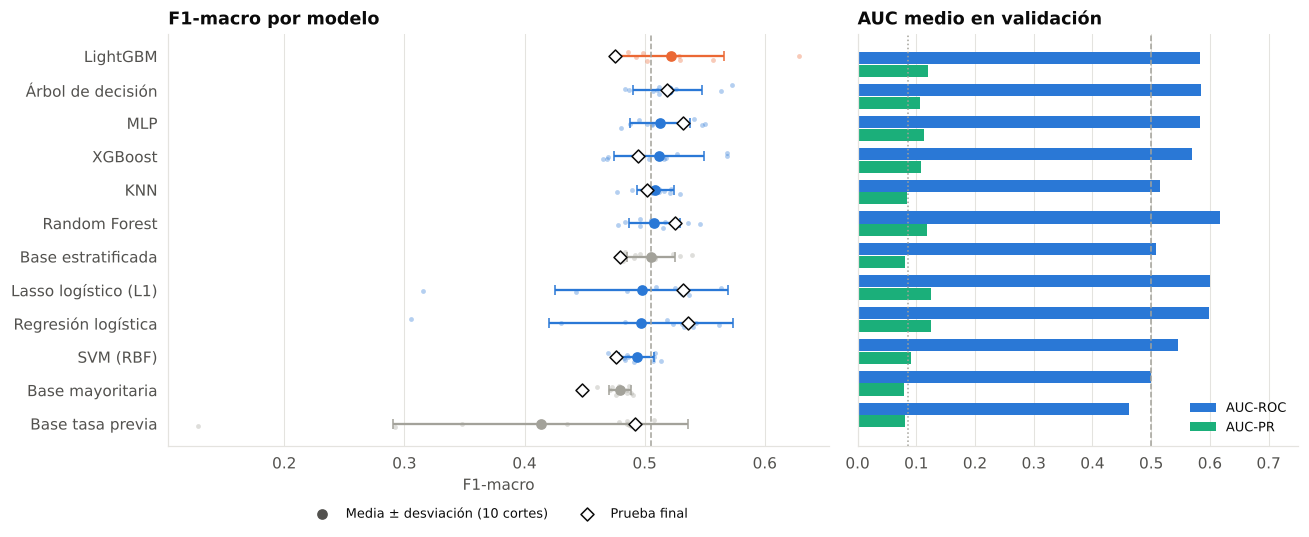

Interpretación (fig10_comparacion_modelos): Los puntos de cada corte se solapan entre la mayoría de los modelos, lo que muestra que el orden en validación es frágil. Arriba quedan LightGBM, Árbol de decisión y MLP; ningún modelo supera a la línea base Base estratificada en todos los cortes. En la mayoría de los modelos ajustados, el rombo de la prueba final queda por debajo de su media de validación, como anticipaba el análisis de deriva.


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), width_ratios=[1.5, 1])
orden_m = media_f1.sort_values().index.tolist()
colores = {m: (GRIS if m in SIN_AJUSTE else (NARANJA if m == MEJOR else AZUL)) for m in orden_m}
for i, mdl in enumerate(orden_m):
    vals = por_corte.loc[por_corte.Modelo == mdl, 'F1-macro']
    ax[0].scatter(vals, np.full(len(vals), i) + rng.uniform(-.15, .15, len(vals)), s=10, color=colores[mdl], alpha=.35, lw=0)
    ax[0].errorbar(vals.mean(), i, xerr=vals.std(), fmt='o', color=colores[mdl], ms=6, capsize=3, lw=1.5)
    ax[0].scatter(prueba.loc[mdl, 'F1-macro'], i, marker='D', s=36, facecolor='white', edgecolor=TINTA, zorder=5)
ax[0].set_yticks(range(len(orden_m))); ax[0].set_yticklabels(orden_m); ax[0].grid(axis='y', visible=False)
ax[0].axvline(media_f1[BASE_REF], color=GRIS, ls='--', lw=1)
ax[0].set_xlabel('F1-macro'); ax[0].set_title('F1-macro por modelo')
ax[0].scatter([], [], marker='o', color=TINTA2, label='Media ± desviación (10 cortes)'); ax[0].scatter([], [], marker='D', facecolor='white', edgecolor=TINTA, label='Prueba final')
ax[0].legend(loc='upper center', bbox_to_anchor=(.5, -.12), ncol=2, fontsize=8.5)
auc_m = por_corte.groupby('Modelo')[['AUC-ROC', 'AUC-PR']].mean().loc[orden_m]
ax[1].barh(np.arange(len(orden_m)) + .2, auc_m['AUC-ROC'], height=.38, color=AZUL, label='AUC-ROC')
ax[1].barh(np.arange(len(orden_m)) - .2, auc_m['AUC-PR'], height=.38, color=AGUA, label='AUC-PR')
ax[1].axvline(.5, color=GRIS, ls='--', lw=1); ax[1].axvline(y_ent.mean(), color=GRIS, ls=':', lw=1)
ax[1].set_yticks(range(len(orden_m))); ax[1].set_yticklabels([]); ax[1].grid(axis='y', visible=False)
ax[1].set_xlim(0, .75); ax[1].set_title('AUC medio en validación'); ax[1].legend(loc='lower right', fontsize=8.5)
fig.tight_layout()
guardar_figura(fig, 'fig10_comparacion_modelos', 'Comparación de los doce modelos: F1-macro en cada corte de validación, media ± desviación y prueba final, y AUC medio en validación')
top_fig = orden.drop(SIN_AJUSTE).index[:3].tolist()
f1_base_cortes = por_corte.loc[por_corte.Modelo == BASE_REF, 'F1-macro'].to_numpy()
gana_todos = [m for m in AJUSTABLES if (por_corte.loc[por_corte.Modelo == m, 'F1-macro'].to_numpy() > f1_base_cortes).all()]
abajo = (prueba['F1-macro'].drop(SIN_AJUSTE) < media_f1.reindex(prueba.index).drop(SIN_AJUSTE)).mean() > .5
RES.update({'gana_todos': gana_todos})
interpretar('fig10_comparacion_modelos', f"Los puntos de cada corte se solapan entre la mayoría de los modelos, lo que muestra que el orden en validación es frágil. Arriba quedan {', '.join(top_fig[:-1])} y {top_fig[-1]}; {'ningún modelo supera a la línea base ' + BASE_REF + ' en todos los cortes' if not gana_todos else 'solo ' + ', '.join(gana_todos) + ' supera' + ('n' if len(gana_todos) > 1 else '') + ' a la línea base ' + BASE_REF + ' en todos los cortes'}. En la mayoría de los modelos ajustados, el rombo de la prueba final queda {'por debajo' if abajo else 'por encima'} de su media de validación{', como anticipaba el análisis de deriva' if abajo else ', pese a la deriva detectada'}.")

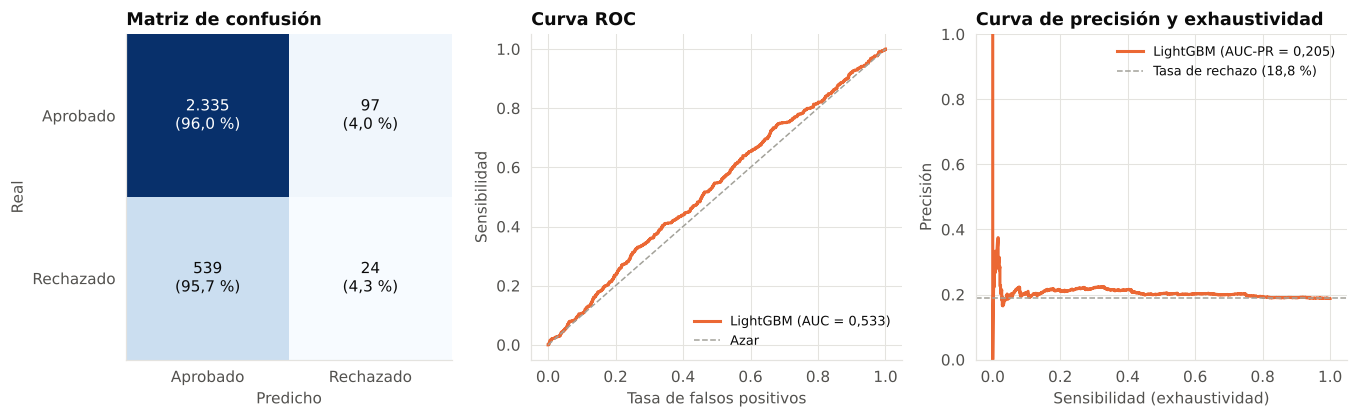

Interpretación (fig11_mejor_modelo): En la prueba final, LightGBM identifica 24 de 563 rechazos (4,3 %) y marca como rechazo 97 de 2.432 aprobados (4,0 %). Su AUC-ROC en prueba es 0,533 y la curva de precisión y exhaustividad queda cerca de la tasa de rechazo en casi todo su recorrido: el modelo ordena las solicitudes apenas mejor que el azar, y con el umbral elegido en validación emite muy pocas alertas porque aprendió una tasa de rechazo que en 2026 se duplicó.


In [14]:
pred, score = predicciones[MEJOR]
cm = confusion_matrix(y_pru, pred)
fpr, tpr, _ = roc_curve(y_pru, score)
prec, rec, _ = precision_recall_curve(y_pru, score)
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.9), width_ratios=[1, 1.1, 1.1])
ax[0].imshow(cm, cmap='Blues'); ax[0].grid(False)
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f'{miles(cm[i, j])}\n({pct(cm[i, j]/cm[i].sum()*100)} %)', ha='center', va='center', color='white' if cm[i, j] > cm.max()*.6 else TINTA, fontsize=10)
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(['Aprobado', 'Rechazado']); ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(['Aprobado', 'Rechazado'])
ax[0].set_xlabel('Predicho'); ax[0].set_ylabel('Real'); ax[0].set_title('Matriz de confusión')
ax[1].plot(fpr, tpr, color=NARANJA, lw=2, label=f"{MEJOR} (AUC = {num(prueba.loc[MEJOR, 'AUC-ROC'])})"); ax[1].plot([0, 1], [0, 1], color=GRIS, ls='--', lw=1, label='Azar')
ax[1].set_xlabel('Tasa de falsos positivos'); ax[1].set_ylabel('Sensibilidad'); ax[1].set_title('Curva ROC'); ax[1].legend(loc='lower right', fontsize=8.5)
ax[2].plot(rec, prec, color=NARANJA, lw=2, label=f"{MEJOR} (AUC-PR = {num(prueba.loc[MEJOR, 'AUC-PR'])})"); ax[2].axhline(y_pru.mean(), color=GRIS, ls='--', lw=1, label=f'Tasa de rechazo ({pct(y_pru.mean()*100)} %)')
ax[2].set_xlabel('Sensibilidad (exhaustividad)'); ax[2].set_ylabel('Precisión'); ax[2].set_title('Curva de precisión y exhaustividad'); ax[2].legend(loc='upper right', fontsize=8.5); ax[2].set_ylim(0, 1)
fig.tight_layout()
guardar_figura(fig, 'fig11_mejor_modelo', f'Desempeño del mejor modelo en validación ({MEJOR}) sobre la prueba final: matriz de confusión, curva ROC y curva de precisión y exhaustividad')
tn, fp, fn, tp = cm.ravel()
RES.update({'cm': [int(tn), int(fp), int(fn), int(tp)]})
interpretar('fig11_mejor_modelo', f"En la prueba final, {MEJOR} identifica {miles(tp)} de {miles(tp+fn)} rechazos ({pct(tp/(tp+fn)*100)} %) y marca como rechazo {miles(fp)} de {miles(tn+fp)} aprobados ({pct(fp/(tn+fp)*100)} %). Su AUC-ROC en prueba es {num(prueba.loc[MEJOR, 'AUC-ROC'])} y la curva de precisión y exhaustividad queda cerca de la tasa de rechazo en casi todo su recorrido: el modelo ordena las solicitudes apenas mejor que el azar, y con el umbral elegido en validación emite muy pocas alertas porque aprendió una tasa de rechazo que en 2026 se duplicó.")

### 3.7 Ablación: el mejor modelo con y sin la ingeniería de características

*Sin ingeniería* = solo las variables originales de la fuente con la codificación mínima (tiempo de residencia, tipo de documento, calidad del solicitante, barrio en one-hot y juramento). Mismos hiperparámetros, mismos cortes y misma prueba.

In [15]:
SIN_FE = ['tiempo_residencia_anios', 'tipo_documento', 'calidad_solicitante', 'barrio_onehot', 'juramento']
filas = []
for etiqueta, variables in (('Con ingeniería de características (variables seleccionadas)', SELECCION), ('Con todas las variables candidatas', TODAS), ('Sin ingeniería de características', SIN_FE)):
    r = evaluar_cv(MEJOR, variables, MEJORES[MEJOR], ent, y_ent, ent['fecha_ingreso'], cv, SEMILLA)
    _, _, _, mt = evaluar_prueba(MEJOR, variables, MEJORES[MEJOR], ent, y_ent, pru, y_pru, SEMILLA)
    registrar_corrida(MEJOR, 'ablacion', MEJORES[MEJOR], resumen(r) | {'F1-macro prueba': mt['F1-macro']}, variables=variables, nota=etiqueta)
    filas.append({'Configuración': etiqueta, 'Variables': len(variables), 'F1-macro (validación)': ms(r['F1-macro']), 'AUC-ROC (validación)': ms(r['AUC-ROC']), 'AUC-PR (validación)': ms(r['AUC-PR']),
                  'F1-macro (prueba)': round(mt['F1-macro'], 3), 'AUC-ROC (prueba)': round(mt['AUC-ROC'], 3), '_f1': r['F1-macro'].mean(), '_auc': r['AUC-ROC'].mean()})
abl = pd.DataFrame(filas)
RES['ablacion'] = abl.drop(columns=['F1-macro (validación)', 'AUC-ROC (validación)', 'AUC-PR (validación)']).to_dict('records')
guardar_tabla(abl.drop(columns=['_f1', '_auc']), 'tabla_ablacion_fe', f'Ablación de la ingeniería de características en el mejor modelo ({MEJOR})')
g_fe = abl.loc[0, '_f1'] - abl.loc[2, '_f1']; g_auc = abl.loc[0, '_auc'] - abl.loc[2, '_auc']
RES.update({'ganancia_fe_f1': float(g_fe), 'ganancia_fe_auc': float(g_auc)})
interpretar('tabla_ablacion_fe', f"En validación, la ingeniería de características casi no cambia el resultado frente a usar solo las variables originales: el F1-macro cambia en {num(g_fe)} y el AUC-ROC en {num(g_auc)}. En la prueba, {'la versión sin ingeniería es mejor' if abl.loc[2, 'F1-macro (prueba)'] > abl.loc[0, 'F1-macro (prueba)'] else 'la versión con ingeniería es mejor'} ({num(abl.loc[2, 'F1-macro (prueba)'])} sin ella frente a {num(abl.loc[0, 'F1-macro (prueba)'])} con ella). Las variables nuevas describen sobre todo el régimen de rechazo y de carga del pasado, y ese régimen cambia en 2026; por eso aportan poco o incluso estorban fuera de muestra. Usar las {len(TODAS)} candidatas en lugar de las {len(SELECCION)} seleccionadas da {num(abl.loc[1, '_f1'])} en validación, de modo que la selección sí mejora frente a no seleccionar.")

Ablación de la ingeniería de características en el mejor modelo (LightGBM)


,Configuración,Variables,F1-macro (validación),AUC-ROC (validación),AUC-PR (validación),F1-macro (prueba),AUC-ROC (prueba)
0,Con ingeniería de características (variables s...,26,"0,522 ± 0,044","0,583 ± 0,070","0,120 ± 0,049",0.475,0.533
1,Con todas las variables candidatas,30,"0,507 ± 0,029","0,556 ± 0,066","0,103 ± 0,039",0.476,0.529
2,Sin ingeniería de características,5,"0,520 ± 0,022","0,598 ± 0,058","0,119 ± 0,039",0.526,0.550


Interpretación (tabla_ablacion_fe): En validación, la ingeniería de características casi no cambia el resultado frente a usar solo las variables originales: el F1-macro cambia en 0,002 y el AUC-ROC en -0,016. En la prueba, la versión sin ingeniería es mejor (0,526 sin ella frente a 0,475 con ella). Las variables nuevas describen sobre todo el régimen de rechazo y de carga del pasado, y ese régimen cambia en 2026; por eso aportan poco o incluso estorban fuera de muestra. Usar las 30 candidatas en lugar de las 26 seleccionadas da 0,507 en validación, de modo que la selección sí mejora frente a no seleccionar.


### 3.8 Para llegar a Excelente

**(a) Compara alternativas:** votación suave de los tres mejores modelos ajustables, en los mismos cortes y con la misma métrica.

In [16]:
from certificados.modelado import ajustar, metricas, pipeline_modelo, puntaje
top3 = media_f1.drop(SIN_AJUSTE).sort_values(ascending=False).index[:3].tolist()

def eval_votacion(Xtr, ytr, Xva, umbral, semilla=SEMILLA):
    """Votación suave: promedio de los puntajes de los tres modelos, cada uno con su balanceo."""
    t0 = time.perf_counter()
    miembros = []
    for m in top3:
        p = {k: v for k, v in MEJORES[m].items() if k != 'umbral'}
        miembros.append(ajustar(pipeline_modelo(m, SELECCION, p, semilla), m, Xtr, ytr))
    seg = time.perf_counter() - t0
    sc = np.mean([puntaje(e, Xva) for e in miembros], axis=0)
    return (sc >= umbral).astype(int), sc, seg

# El umbral de la votación se elige con los cortes de validación (rejilla), nunca con la prueba.
scores_v = []
for k, (tr, va) in enumerate(cortes, start=1):
    _, sc, seg = eval_votacion(ent.iloc[tr], y_ent.iloc[tr], ent.iloc[va], .5)
    scores_v.append((va, sc, seg))
rejilla = np.round(np.arange(.05, .951, .01), 2)
f1_rej = [np.mean([metricas(y_ent.iloc[va], (sc >= u).astype(int), sc)['F1-macro'] for va, sc, _ in scores_v]) for u in rejilla]
U_VOT = float(rejilla[int(np.argmax(f1_rej))])
filas = []
for k, (va, sc, seg) in enumerate(scores_v, start=1):
    filas.append({'Modelo': 'Votación top 3', 'Partición': k, **metricas(y_ent.iloc[va], (sc >= U_VOT).astype(int), sc), 'Tiempo de entrenamiento (s)': seg})
r_vot = pd.DataFrame(filas)
pv, sv, segv = eval_votacion(ent, y_ent, pru, U_VOT)
mt_vot = {**metricas(y_pru, pv, sv), 'Tiempo de entrenamiento (s)': segv}
registrar_corrida('Votación top 3', 'validacion_10_cortes', {'miembros': top3, 'umbral': U_VOT}, resumen(r_vot))
registrar_corrida('Votación top 3', 'prueba_final', {'miembros': top3, 'umbral': U_VOT}, mt_vot)
comp = pd.DataFrame([{'Modelo': m, 'F1-macro (validación)': ms(g['F1-macro']), 'AUC-ROC (validación)': ms(g['AUC-ROC']), 'F1-macro (prueba)': round(t['F1-macro'], 3), 'AUC-ROC (prueba)': round(t['AUC-ROC'], 3)}
                     for m, g, t in [(m, por_corte[por_corte.Modelo == m], prueba.loc[m]) for m in top3] + [('Votación top 3', r_vot, pd.Series(mt_vot))]])
guardar_tabla(comp, 'tabla_votacion', f'Votación suave de los tres mejores modelos frente a cada uno por separado (umbral {pct(U_VOT, 2)} elegido en validación)')
mpp_v = r_vot[['Modelo', 'Partición', 'F1-macro', 'AUC-ROC', 'AUC-PR', 'MCC', 'Sensibilidad rechazo', 'Precisión rechazo', 'Tiempo de entrenamiento (s)']].copy()
mpp_v.insert(1, 'Familia', 'e. Combinación'); mpp_v.insert(3, 'Métrica principal', 'F1-macro'); mpp_v.insert(4, 'Valor', mpp_v['F1-macro'])
pd.concat([mpp, mpp_v], ignore_index=True).round(5).to_csv(TAB/'metricas_por_particion.csv', index=False, encoding='utf-8-sig')
RES.update({'top3': top3, 'vot_cv': float(r_vot['F1-macro'].mean()), 'vot_te': float(mt_vot['F1-macro']), 'vot_auc_cv': float(r_vot['AUC-ROC'].mean()), 'u_vot': U_VOT})
mejor_ind_te = max(prueba.loc[m, 'F1-macro'] for m in top3)
d_f1_cv, d_auc_cv = r_vot['F1-macro'].mean() - media_f1[MEJOR], r_vot['AUC-ROC'].mean() - por_corte.loc[por_corte.Modelo == MEJOR, 'AUC-ROC'].mean()
d_f1_te = mt_vot['F1-macro'] - prueba.loc[MEJOR, 'F1-macro']
interpretar('tabla_votacion', f"La votación de {', '.join(top3[:-1])} y {top3[-1]} obtiene F1-macro de {num(r_vot['F1-macro'].mean())} en validación y {num(mt_vot['F1-macro'])} en prueba, frente a {num(media_f1[MEJOR])} y {num(prueba.loc[MEJOR, 'F1-macro'])} de {MEJOR}. La combinación sube el AUC-ROC de validación en {num(d_auc_cv)} y el F1-macro en {num(d_f1_cv)}, una diferencia menor que la desviación entre cortes; en la prueba gana {num(d_f1_te)} de F1-macro, porque promediar modelos distintos amortigua el error del individual. Aun así, sigue {'por debajo' if mt_vot['F1-macro'] - prueba.loc[BASE_REF, 'F1-macro'] < .05 else 'por encima'} del umbral de mejora de 0,05 sobre la línea base, de modo que la complejidad adicional todavía no se traduce en un modelo útil.")

Votación suave de los tres mejores modelos frente a cada uno por separado (umbral 0,55 elegido en validación)


,Modelo,F1-macro (validación),AUC-ROC (validación),F1-macro (prueba),AUC-ROC (prueba)
0,LightGBM,"0,522 ± 0,044","0,583 ± 0,070",0.475,0.533
1,Árbol de decisión,"0,519 ± 0,029","0,585 ± 0,070",0.518,0.569
2,MLP,"0,513 ± 0,025","0,583 ± 0,078",0.532,0.541
3,Votación top 3,"0,528 ± 0,045","0,607 ± 0,081",0.510,0.572


Interpretación (tabla_votacion): La votación de LightGBM, Árbol de decisión y MLP obtiene F1-macro de 0,528 en validación y 0,510 en prueba, frente a 0,522 y 0,475 de LightGBM. La combinación sube el AUC-ROC de validación en 0,024 y el F1-macro en 0,006, una diferencia menor que la desviación entre cortes; en la prueba gana 0,035 de F1-macro, porque promediar modelos distintos amortigua el error del individual. Aun así, sigue por debajo del umbral de mejora de 0,05 sobre la línea base, de modo que la complejidad adicional todavía no se traduce en un modelo útil.


**(b) Demuestra que se sostiene:** se repite la evaluación con cinco semillas y con otras dos formas de partir (5 cortes, y ventana deslizante de 120 días de entrenamiento), y se mide si el orden de los modelos se mantiene (tau de Kendall frente al orden principal).

In [17]:
SEMILLAS = [0, 1, 2, 3, 4]
esquemas = {'10 cortes, semilla 42 (principal)': (cv, [SEMILLA])}
esquemas['10 cortes, 5 semillas'] = (cv, SEMILLAS)
esquemas['5 cortes'] = (TimeSeriesSplitPorDia(5), [SEMILLA])
esquemas['10 cortes, ventana de 120 días'] = (TimeSeriesSplitPorDia(10, max_train_dias=120), [SEMILLA])
f1_esq = {}
for nombre_e, (cv_e, semillas) in esquemas.items():
    vals = {}
    for m in AJUSTABLES + ['Base estratificada']:
        if nombre_e.endswith('(principal)'):
            vals[m] = media_f1[m]
            continue
        rs = [evaluar_cv(m, SELECCION, MEJORES.get(m, {}), ent, y_ent, ent['fecha_ingreso'], cv_e, s)['F1-macro'].mean() for s in semillas]
        vals[m] = float(np.mean(rs))
        registrar_corrida(m, 'robustez', MEJORES.get(m, {}), {'F1-macro': vals[m], 'F1-macro sd entre semillas': float(np.std(rs))}, semilla=','.join(map(str, semillas)), variables=SELECCION, nota=nombre_e)
    f1_esq[nombre_e] = pd.Series(vals)
rob = pd.DataFrame(f1_esq)
ref = rob.iloc[:, 0]
filas = []
for col in rob.columns:
    tau = stats.kendalltau(ref, rob[col]).statistic
    filas.append({'Esquema': col, 'Mejor modelo': rob[col].drop('Base estratificada').idxmax(), 'F1-macro del mejor': round(rob[col].drop('Base estratificada').max(), 3),
                  'F1-macro base estratificada': round(rob.loc['Base estratificada', col], 3), 'Tau de Kendall con el orden principal': round(tau, 2),
                  f'Posición de {MEJOR}': int(rob[col].rank(ascending=False)[MEJOR])})
tabla_rob = pd.DataFrame(filas)
guardar_tabla(tabla_rob, 'tabla_robustez_modelos', 'Estabilidad del orden de los modelos al cambiar la semilla y la forma de partir los datos')
rob.round(4).to_csv(TAB/'tabla_robustez_f1_por_esquema.csv', encoding='utf-8-sig')
RES.update({'robustez': tabla_rob.to_dict('records')})
taus = tabla_rob['Tau de Kendall con el orden principal'].iloc[1:]
col_v = '10 cortes, ventana de 120 días'
lineales = ['Regresión logística', 'Lasso logístico (L1)']
arboles = ['Árbol de decisión', 'Random Forest', 'XGBoost', 'LightGBM']
interpretar('tabla_robustez_modelos', f"El orden de los modelos {'se mantiene bastante' if taus.min() >= .6 else ('se mantiene solo en parte' if taus.min() >= .3 else 'cambia mucho')} al variar la semilla y la partición (tau de Kendall entre {num(taus.min(), 2)} y {num(taus.max(), 2)}), y {MEJOR} queda en las posiciones {', '.join(map(str, tabla_rob[f'Posición de {MEJOR}']))} según el esquema. El cambio más fuerte aparece con la ventana de 120 días: los modelos lineales caen a un F1-macro de {num(rob.loc[lineales, col_v].min())} a {num(rob.loc[lineales, col_v].max())}, mientras que los de árboles quedan entre {num(rob.loc[arboles, col_v].min())} y {num(rob.loc[arboles, col_v].max())}. La conclusión que sí se sostiene en todos los esquemas es que la diferencia entre el mejor modelo y la línea base estratificada no supera {num((tabla_rob['F1-macro del mejor'] - tabla_rob['F1-macro base estratificada']).max())}.")

Estabilidad del orden de los modelos al cambiar la semilla y la forma de partir los datos


,Esquema,Mejor modelo,F1-macro del mejor,F1-macro base estratificada,Tau de Kendall con el orden principal,Posición de LightGBM
0,"10 cortes, semilla 42 (principal)",LightGBM,0.522,0.505,1.00,1
1,"10 cortes, 5 semillas",Árbol de decisión,0.517,0.492,0.51,2
2,5 cortes,XGBoost,0.522,0.498,0.38,2
3,"10 cortes, ventana de 120 días",Árbol de decisión,0.520,0.504,0.51,5


Interpretación (tabla_robustez_modelos): El orden de los modelos se mantiene solo en parte al variar la semilla y la partición (tau de Kendall entre 0,38 y 0,51), y LightGBM queda en las posiciones 1, 2, 2, 5 según el esquema. El cambio más fuerte aparece con la ventana de 120 días: los modelos lineales caen a un F1-macro de 0,360 a 0,371, mientras que los de árboles quedan entre 0,507 y 0,520. La conclusión que sí se sostiene en todos los esquemas es que la diferencia entre el mejor modelo y la línea base estratificada no supera 0,025.


**(c) Suma contexto:** ablación por grupos. Se quita un grupo de variables a la vez del mejor modelo.

In [18]:
filas = []
for grupo, vs in GRUPOS.items():
    variables = [v for v in SELECCION if v not in vs]
    if len(variables) == len(SELECCION):
        continue
    r = evaluar_cv(MEJOR, variables, MEJORES[MEJOR], ent, y_ent, ent['fecha_ingreso'], cv, SEMILLA)
    _, _, _, mt = evaluar_prueba(MEJOR, variables, MEJORES[MEJOR], ent, y_ent, pru, y_pru, SEMILLA)
    registrar_corrida(MEJOR, 'ablacion_grupos', MEJORES[MEJOR], resumen(r) | {'F1-macro prueba': mt['F1-macro']}, variables=variables, nota=f'sin {grupo}')
    filas.append({'Grupo retirado': grupo, 'Variables retiradas': len(SELECCION) - len(variables), 'F1-macro (validación)': round(r['F1-macro'].mean(), 3),
                  'Cambio F1-macro (validación)': round(r['F1-macro'].mean() - media_f1[MEJOR], 3), 'AUC-ROC (validación)': round(r['AUC-ROC'].mean(), 3),
                  'Cambio AUC-ROC (validación)': round(r['AUC-ROC'].mean() - por_corte.loc[por_corte.Modelo == MEJOR, 'AUC-ROC'].mean(), 3), 'F1-macro (prueba)': round(mt['F1-macro'], 3)})
abl_g = pd.DataFrame(filas).sort_values('Cambio AUC-ROC (validación)')
guardar_tabla(abl_g, 'tabla_ablacion_grupos', f'Cambio en el desempeño de {MEJOR} al retirar cada grupo de variables')
RES['ablacion_grupos'] = abl_g.to_dict('records')
g1 = abl_g.iloc[0]
interpretar('tabla_ablacion_grupos', f"El grupo que más aporta es {g1['Grupo retirado']}: sin él, el AUC-ROC de validación cambia en {num(g1['Cambio AUC-ROC (validación)'])} y el F1-macro en {num(g1['Cambio F1-macro (validación)'])}. Los cambios del F1-macro son pequeños frente a su desviación entre cortes, así que la ablación por grupos se ampliará con la prueba estadística del ACA 3. En la prueba, en cambio, quitar los rezagos y ventanas {'mejora' if abl_g.set_index('Grupo retirado').loc['Rezagos y ventanas', 'F1-macro (prueba)'] > prueba.loc[MEJOR, 'F1-macro'] else 'empeora'} el F1-macro ({num(abl_g.set_index('Grupo retirado').loc['Rezagos y ventanas', 'F1-macro (prueba)'])} frente a {num(prueba.loc[MEJOR, 'F1-macro'])}), coherente con la deriva: esas variables resumen un régimen de rechazo que ya no se cumple en 2026.")

Cambio en el desempeño de LightGBM al retirar cada grupo de variables


,Grupo retirado,Variables retiradas,F1-macro (validación),Cambio F1-macro (validación),AUC-ROC (validación),Cambio AUC-ROC (validación),F1-macro (prueba)
2,Barrio,3,0.495,-0.027,0.513,-0.070,0.455
0,Residencia,3,0.508,-0.013,0.552,-0.031,0.473
1,Solicitante y documento,4,0.513,-0.009,0.552,-0.030,0.497
3,Calendario,12,0.514,-0.008,0.572,-0.010,0.467
4,Rezagos y ventanas,4,0.513,-0.009,0.581,-0.002,0.540


Interpretación (tabla_ablacion_grupos): El grupo que más aporta es Barrio: sin él, el AUC-ROC de validación cambia en -0,070 y el F1-macro en -0,027. Los cambios del F1-macro son pequeños frente a su desviación entre cortes, así que la ablación por grupos se ampliará con la prueba estadística del ACA 3. En la prueba, en cambio, quitar los rezagos y ventanas mejora el F1-macro (0,540 frente a 0,475), coherente con la deriva: esas variables resumen un régimen de rechazo que ya no se cumple en 2026.


**(d) Tradúcelo a decisiones:** qué significa el resultado del mejor modelo por cada 100 solicitudes de la prueba.

In [19]:
n100 = 100/len(y_pru)
dec = pd.DataFrame([
    {'Situación': 'Solicitudes que la oficina recibe', 'Por cada 100 solicitudes': 100.0},
    {'Situación': 'Solicitudes que terminan rechazadas', 'Por cada 100 solicitudes': round((tp+fn)*n100, 1)},
    {'Situación': 'Alertas de posible rechazo que emite el modelo', 'Por cada 100 solicitudes': round((tp+fp)*n100, 1)},
    {'Situación': 'Alertas que sí terminan en rechazo', 'Por cada 100 solicitudes': round(tp*n100, 1)},
    {'Situación': 'Rechazos que el modelo no anticipa', 'Por cada 100 solicitudes': round(fn*n100, 1)},
    {'Situación': 'Alertas sobre solicitudes que se aprueban', 'Por cada 100 solicitudes': round(fp*n100, 1)},
])
guardar_tabla(dec, 'tabla_decision', f'Lectura del mejor modelo ({MEJOR}) en la prueba final, expresada por cada 100 solicitudes')
prec_alerta = tp/(tp+fp)*100 if tp+fp else 0
RES.update({'dec': dec.to_dict('records'), 'prec_alerta': prec_alerta, 'sens_rechazo': tp/(tp+fn)*100})
interpretar('tabla_decision', f"De cada 100 solicitudes de la prueba, {pct((tp+fn)*n100)} terminan rechazadas. El modelo emite {pct((tp+fp)*n100)} alertas y {pct(tp*n100)} de ellas aciertan: de cada 100 alertas, unas {pct(prec_alerta, 0)} corresponden a un rechazo real, frente a {pct(y_pru.mean()*100, 0)} si se revisaran solicitudes al azar. Con una precisión tan cercana a la del azar, el modelo todavía no serviría ni siquiera para priorizar una revisión previa de requisitos, y mucho menos para decidir un trámite.")

Lectura del mejor modelo (LightGBM) en la prueba final, expresada por cada 100 solicitudes


,Situación,Por cada 100 solicitudes
0,Solicitudes que la oficina recibe,100.0
1,Solicitudes que terminan rechazadas,18.8
2,Alertas de posible rechazo que emite el modelo,4.0
3,Alertas que sí terminan en rechazo,0.8
4,Rechazos que el modelo no anticipa,18.0
5,Alertas sobre solicitudes que se aprueban,3.2


Interpretación (tabla_decision): De cada 100 solicitudes de la prueba, 18,8 terminan rechazadas. El modelo emite 4,0 alertas y 0,8 de ellas aciertan: de cada 100 alertas, unas 20 corresponden a un rechazo real, frente a 19 si se revisaran solicitudes al azar. Con una precisión tan cercana a la del azar, el modelo todavía no serviría ni siquiera para priorizar una revisión previa de requisitos, y mucho menos para decidir un trámite.


## 4. Criterio de éxito del protocolo, bitácora y trazabilidad

In [20]:
crit = pd.DataFrame([
    {'Condición del protocolo (Tabla 3)': 'Superar a la línea base en F1-macro por al menos 0,05 en validación', 'Resultado': f'{num(dif_cv)} ({MEJOR} frente a {BASE_REF})', '¿Se cumple?': 'Sí' if dif_cv >= .05 else 'No'},
    {'Condición del protocolo (Tabla 3)': 'Confirmarlo en la prueba final', 'Resultado': f'{num(dif_te)}', '¿Se cumple?': 'Sí' if dif_te >= .05 else 'No'},
    {'Condición del protocolo (Tabla 3)': 'Intervalos de confianza del 95 % que no se crucen y prueba estadística', 'Resultado': 'Se calculan en el ACA 3 con metricas_por_particion.csv', '¿Se cumple?': 'Pendiente'},
])
guardar_tabla(crit, 'tabla_criterio_exito', 'Verificación preliminar del criterio de éxito fijado en el protocolo de evaluación')
interpretar('tabla_criterio_exito', f"Con la evidencia de esta entrega, el criterio de éxito {'se cumple de forma preliminar' if RES['exito'] else 'no se cumple'}: la mejora sobre la línea base es de {num(dif_cv)} en validación y de {num(dif_te)} en prueba, {'por encima' if RES['exito'] else 'por debajo'} del mínimo de 0,05 fijado antes de entrenar. Según la regla de la arquitectura, {'el tablero podrá mostrar predicciones si el ACA 3 lo confirma' if RES['exito'] else 'el tablero no debe mostrar predicciones de rechazo y se limitará a indicadores de calidad, salvo que el ACA 3 cambie esta conclusión'}.")

bit = pd.DataFrame([
 (HOY, 'Escribir las reglas como transformadores de scikit-learn', 'Funciones sueltas en el cuaderno', 'Recomendación del docente: el mismo código sirve para reportes de calidad y para el Pipeline del objetivo 3', 'tabla_reglas_pipeline; tests/'),
 (HOY, 'Dejar las reglas que quitan filas fuera del Pipeline de modelado', 'Incluirlas en el Pipeline', 'scikit-learn exige que X e y conserven el mismo número de filas', 'src/certificados/reglas.py'),
 (HOY, 'Validar los scripts contra la base del ACA 1 y con fallas inyectadas', 'Revisar a ojo la salida', 'La equivalencia exacta y la inyección miden el efecto de cada regla con evidencia', 'tabla_equivalencia_scripts; tabla_inyeccion_fallas'),
 (HOY, 'Mover el corte de prueba al inicio del día del percentil 80', 'Cortar exactamente en el 80 % de las filas', 'Un mismo día quedaba partido entre entrenamiento y prueba', 'tabla_particion'),
 (HOY, 'Aplicar TimeSeriesSplit sobre días y no sobre filas', 'TimeSeriesSplit sobre filas', 'Las variables de rezago son iguales para todo un día y permitirían reconocer días partidos', 'src/certificados/caracteristicas.py'),
 (HOY, 'Desfase de 14 días en las tasas de rechazo previas', 'Usar el día anterior', 'No hay fecha de cierre: no se sabe cuándo se conoce la decisión de una solicitud', 'tabla_variables_creadas'),
 (HOY, 'No usar año ni días desde el inicio como variables', 'Incluir la tendencia', 'La prueba está en 2026: el modelo tendría que extrapolar una tendencia que cambia de régimen', 'tabla_deriva'),
 (HOY, 'Codificar el barrio con TargetEncoder dentro del Pipeline', 'One-hot de 117 barrios; frecuencia sobre toda la base', 'Evita columnas dispersas y la fuga de frecuencia_barrio del EDA', 'tabla_variables_creadas'),
 (HOY, 'Selección con información mutua frente a sondas aleatorias y LASSO', 'RFE; Boruta completo', 'Dos criterios distintos y baratos; las sondas dan un umbral objetivo de ruido', 'tabla_seleccion_variables'),
 (HOY, 'Buscar el umbral de decisión junto con los hiperparámetros', 'Umbral fijo de 0,5', 'Con pesos de clase, el umbral de 0,5 genera demasiadas alertas y baja el F1-macro', 'tabla_hiperparametros'),
 (HOY, 'Balanceo con pesos de clase; sobremuestreo aleatorio solo para KNN', 'SMOTE para todos', 'Los pesos no crean registros sintéticos; KNN no admite pesos', 'src/certificados/modelado.py'),
 (HOY, f'{N_PRUEBAS_OPTUNA} pruebas de Optuna por modelo', 'Más pruebas para los modelos complejos', 'La comparación solo es justa con el mismo presupuesto', 'optuna_trials.csv'),
 (HOY, 'No entrenar LSTM ni GRU', 'Secuencias diarias de solicitudes', 'Cada fila es una solicitud independiente sin historia por persona; la parte temporal ya entra con rezagos y ventanas', 'tabla_variables_creadas'),
 (HOY, f'Elegir {MEJOR} como mejor modelo', 'Elegir por la prueba final', 'El protocolo elige por la media de F1-macro en validación; la prueba solo confirma', 'tabla_resultados_modelos'),
], columns=['Fecha', 'Decisión', 'Alternativas consideradas', 'Por qué se eligió', 'Evidencia'])
guardar_tabla(bit, 'tabla_bitacora_aca2', 'Bitácora de decisiones del ACA 2')

exp = pd.DataFrame(CORRIDAS)
exp.to_csv(EXPERIMENTOS, index=False, encoding='utf-8-sig')
RES.update({'n_corridas': len(exp), 'semilla': SEMILLA, 'n_pruebas_optuna': N_PRUEBAS_OPTUNA, 'segundos_total': round(time.perf_counter() - INICIO, 1)})
(BASE/'results/resultados_aca2.json').write_text(json.dumps(RES, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
print(f"{len(exp)} corridas registradas en results/experiments.csv. Ejecución completa en {RES['segundos_total']} s")

Verificación preliminar del criterio de éxito fijado en el protocolo de evaluación


,Condición del protocolo (Tabla 3),Resultado,¿Se cumple?
0,Superar a la línea base en F1-macro por al men...,"0,016 (LightGBM frente a Base estratificada)",No
1,Confirmarlo en la prueba final,"-0,005",No
2,Intervalos de confianza del 95 % que no se cru...,Se calculan en el ACA 3 con metricas_por_parti...,Pendiente


Interpretación (tabla_criterio_exito): Con la evidencia de esta entrega, el criterio de éxito no se cumple: la mejora sobre la línea base es de 0,016 en validación y de -0,005 en prueba, por debajo del mínimo de 0,05 fijado antes de entrenar. Según la regla de la arquitectura, el tablero no debe mostrar predicciones de rechazo y se limitará a indicadores de calidad, salvo que el ACA 3 cambie esta conclusión.
Bitácora de decisiones del ACA 2


,Fecha,Decisión,Alternativas consideradas,Por qué se eligió,Evidencia
0,2026-11-14,Escribir las reglas como transformadores de sc...,Funciones sueltas en el cuaderno,Recomendación del docente: el mismo código sir...,tabla_reglas_pipeline; tests/
1,2026-11-14,Dejar las reglas que quitan filas fuera del Pi...,Incluirlas en el Pipeline,scikit-learn exige que X e y conserven el mism...,src/certificados/reglas.py
2,2026-11-14,Validar los scripts contra la base del ACA 1 y...,Revisar a ojo la salida,La equivalencia exacta y la inyección miden el...,tabla_equivalencia_scripts; tabla_inyeccion_fa...
3,2026-11-14,Mover el corte de prueba al inicio del día del...,Cortar exactamente en el 80 % de las filas,Un mismo día quedaba partido entre entrenamien...,tabla_particion
4,2026-11-14,Aplicar TimeSeriesSplit sobre días y no sobre ...,TimeSeriesSplit sobre filas,Las variables de rezago son iguales para todo ...,src/certificados/caracteristicas.py
5,2026-11-14,Desfase de 14 días en las tasas de rechazo pre...,Usar el día anterior,No hay fecha de cierre: no se sabe cuándo se c...,tabla_variables_creadas
6,2026-11-14,No usar año ni días desde el inicio como varia...,Incluir la tendencia,La prueba está en 2026: el modelo tendría que ...,tabla_deriva
7,2026-11-14,Codificar el barrio con TargetEncoder dentro d...,One-hot de 117 barrios; frecuencia sobre toda ...,Evita columnas dispersas y la fuga de frecuenc...,tabla_variables_creadas
8,2026-11-14,Selección con información mutua frente a sonda...,RFE; Boruta completo,Dos criterios distintos y baratos; las sondas ...,tabla_seleccion_variables
9,2026-11-14,Buscar el umbral de decisión junto con los hip...,"Umbral fijo de 0,5","Con pesos de clase, el umbral de 0,5 genera de...",tabla_hiperparametros


334 corridas registradas en results/experiments.csv. Ejecución completa en 545.3 s
